In [1]:
# Load the datasets

In [16]:
import os, sys, re, ast
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
glider = xr.open_dataset("../data/processed/CP05MOAS-GL379.deployment0008.merged.nc")
glider

<xarray.Dataset> Size: 3GB
Dimensions:                                    (time: 604054, bin: 30)
Coordinates:
    lon                                        (time) float64 5MB ...
    depth                                      (time) float64 5MB ...
    lat                                        (time) float64 5MB ...
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 5MB 2019...
Data variables: (12/67)
    corrected_echo_intensity_beam4             (time, bin) float64 145MB ...
    num_cells                                  (time) float32 2MB ...
    ensemble_number                            (time) float32 2MB ...
    transducer_depth                           (time) float32 2MB ...
    corrected_echo_intensity_beam3             (time, bin) float64 145MB ...
    corrected_echo_intensity_beam2             (time, bin) float64 145MB ...
    ...                                         ...
    glider_precise_lon                         (time) float64 5MB ...
    glider_roll                                (time) float64 5MB ...
    profile_id                                 (time) int64 5MB ...
    vendor_qc_flag                             (time, bin) int64 145MB ...
    waypoint_lat                               (time) float64 5MB ...
    waypoint_lon                               (time) float64 5MB ...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [5]:
bottom_track = xr.open_dataset("../data/raw//CP05MOAS-GL379-01-ADCPAM000.deployment0008.adcp_bottom_track.nc")
bottom_track.load()

<xarray.Dataset> Size: 167MB
Dimensions:                          (time: 604054)
Coordinates:
    lon                              (time) float64 5MB -70.6 -70.6 ... -70.53
    depth                            (time) float64 5MB 0.2459 0.306 ... 102.2
  * time                             (time) datetime64[ns] 5MB 2019-09-27T12:...
    lat                              (time) float64 5MB 40.05 40.05 ... 40.12
Data variables: (12/51)
    bt_beam4_ref_intensity           (time) float32 2MB 67.0 66.0 ... nan nan
    bt_beam1_percent_good            (time) float32 2MB nan nan nan ... nan nan
    bt_beam2_rssi_amplitude          (time) float32 2MB nan nan ... 158.0 162.0
    bt_beam4_ref_correlation         (time) float32 2MB 109.0 104.0 ... nan nan
    bt_beam2_correlation             (time) float32 2MB nan nan ... 255.0 255.0
    bt_gain                          (time) float32 2MB nan 15.0 ... 15.0 15.0
    ...                               ...
    bt_upward_ref_layer_velocity     (time) float32 2MB -292.0 -81.0 ... nan nan
    bt_beam3_correlation             (time) float32 2MB nan nan ... 255.0 255.0
    bt_beam3_range                   (time) float64 5MB nan nan ... 2.21e+03
    bt_beam2_ref_intensity           (time) float32 2MB 71.0 72.0 ... nan nan
    bt_beam2_eval_amp                (time) float32 2MB nan nan ... 56.0 55.0
    bt_ref_layer_near                (time) float32 2MB 80.0 80.0 ... 0.0 0.0
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_bottom_track_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -71.18116628263888
    geospatial_lon_max:                 -70.30236914112658
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [7]:
def remove_bottom_track(glider, bottom_track):
    """Remove the bottom track from the glider DVL water velocities"""
    # Adjust the eastward velocities
    east_bottom_track = bottom_track['bt_eastward_velocity'] / 1000
    eastward_velocity = glider['eastward_seawater_velocity'] - east_bottom_track

    # Adjust the nortward velocities
    north_bottom_track = bottom_track['bt_northward_velocity'] / 1000
    northward_velocity = glider['northward_seawater_velocity'] - north_bottom_track

    # Add the results into the glider dataset
    glider['corrected_eastward_velocity'] = eastward_velocity
    glider['corrected_eastward_velocity'].attrs = {
        'standard_name': 'eastward_seawater_velocity',
        'long_name': 'Motion-Corrected Eastward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Eastward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the eastward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'eastward_seawater_velocity bt_eastward_velocity'
    }

    glider['corrected_northward_velocity'] = northward_velocity
    glider['corrected_northward_velocity'].attrs = {
        'standard_name': 'northward_seawater_velocity',
        'long_name': 'Motion-Corrected Northward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Northward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the northward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'northward_seawater_velocity bt_northward_velocity'
    }

    return glider
    

In [9]:
# Add the eastward and northward bottom track velocities to the glider dataset
glider['bottom_track_eastward_velocity'] = bottom_track['bt_eastward_velocity']
glider['bottom_track_northward_velocity'] = bottom_track['bt_northward_velocity']

### Bottom-Track Statistics
Next, calculate some of the statistics for the bottom track data

##### Glider 379 - Deployment 8 - Dive 731

In [11]:
dive731 = glider.where(glider['profile_id'] == 731, drop=True)
dive731

<xarray.Dataset> Size: 1MB
Dimensions:                                    (time: 221, bin: 30)
Coordinates:
    lon                                        (time) float64 2kB -70.88 ... ...
    depth                                      (time) float64 2kB 0.0 ... 0.0
    lat                                        (time) float64 2kB 40.1 ... 40.1
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 2kB 2019...
Data variables: (12/69)
    corrected_echo_intensity_beam4             (time, bin) float64 53kB 50.63...
    num_cells                                  (time) float32 884B 30.0 ... 30.0
    ensemble_number                            (time) float32 884B 1.0 ... 221.0
    transducer_depth                           (time) float32 884B 135.0 ... ...
    corrected_echo_intensity_beam3             (time, bin) float64 53kB 62.22...
    corrected_echo_intensity_beam2             (time, bin) float64 53kB 58.56...
    ...                                         ...
    profile_id                                 (time) float64 2kB 731.0 ... 7...
    vendor_qc_flag                             (time, bin) float64 53kB 1.0 ....
    waypoint_lat                               (time) float64 2kB 39.83 ... 3...
    waypoint_lon                               (time) float64 2kB -71.17 ... ...
    bottom_track_eastward_velocity             (time) float32 884B nan ... 200.0
    bottom_track_northward_velocity            (time) float32 884B nan ... -1...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [13]:
# Calculate the mean northward and eastward bottom_track velocitys
eastward_velocity = dive731['bottom_track_eastward_velocity'].mean(dim='time', skipna=True).values
northward_velocity = dive731['bottom_track_northward_velocity'].mean(dim='time', skipna=True).values
eastward_velocity, northward_velocity

(array(180.6378, dtype=float32), array(-178.70079, dtype=float32))

In [14]:
eastward_velocity = dive731['bottom_track_eastward_velocity'].std(dim='time', skipna=True).values
northward_velocity = dive731['bottom_track_northward_velocity'].std(dim='time', skipna=True).values
eastward_velocity, northward_velocity

(array(103.54387, dtype=float32), array(79.082664, dtype=float32))

In [92]:
sog = np.sqrt(dive731['bottom_track_eastward_velocity']**2 + dive731['bottom_track_northward_velocity']**2)
glider['speed_over_ground'] = np.sqrt(glider['bottom_track_eastward_velocity']**2 + glider['bottom_track_northward_velocity']**2)

Text(0.5, 0, 'Bottom Track - Speed over Ground [mm/s]')

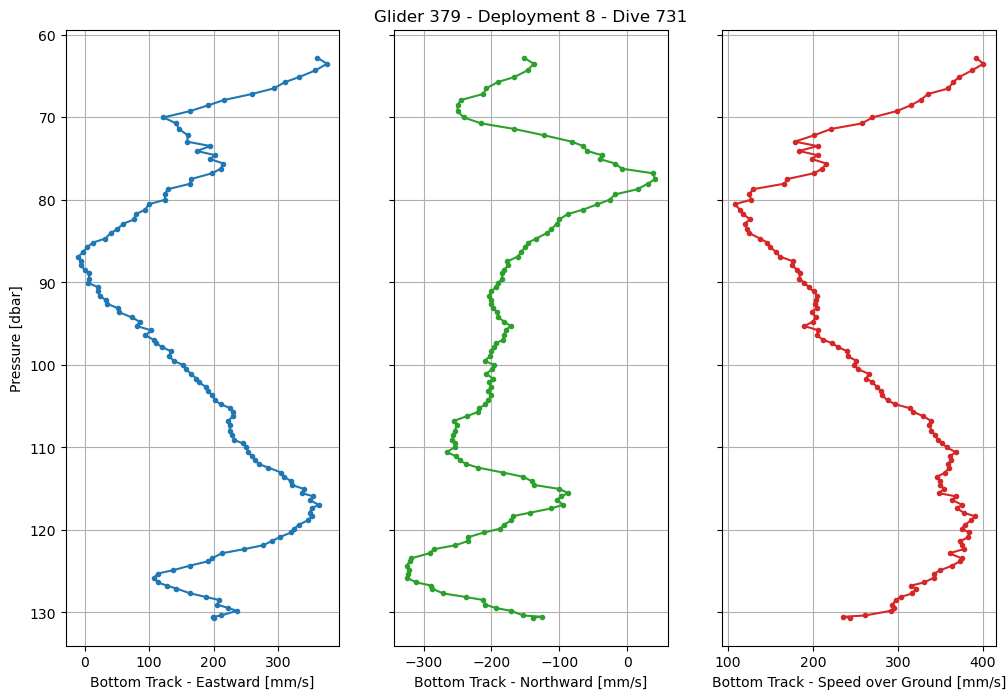

In [48]:
# Plot the profiles
fig, ax = plt.subplots(nrows=1, ncols = 3, figsize=(12, 8), sharey=True)

ax[0].plot(dive731['bottom_track_eastward_velocity'], dive731['ctd_pressure'], marker='.')
ax[0].grid()
ax[0].set_xlabel('Bottom Track - Eastward [mm/s]')
ax[0].set_ylabel('Pressure [dbar]')
ax[0].invert_yaxis()

ax[1].plot(dive731['bottom_track_northward_velocity'], dive731['ctd_pressure'], marker='.', color='tab:green')
ax[1].grid()
ax[1].set_xlabel('Bottom Track - Northward [mm/s]')
ax[1].set_title('Glider 379 - Deployment 8 - Dive 731')

ax[2].plot(sog, dive731['ctd_pressure'], marker='.', color='tab:red')
ax[2].grid()
ax[2].set_xlabel('Bottom Track - Speed over Ground [mm/s]')

# ax[3].plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
# ax[3].grid()
# ax[3].set_xlabel('Vertical Speed (dZ/dt) [mm/s]')


In [49]:
fig.savefig("../results/figures/GL379.deployment0008.dive731.bottom_track.png", facecolor='white', transparent=False, bbox_inches='tight')

Text(0.5, 1.0, 'Glider 379 - Deployment 8 - Dive 731')

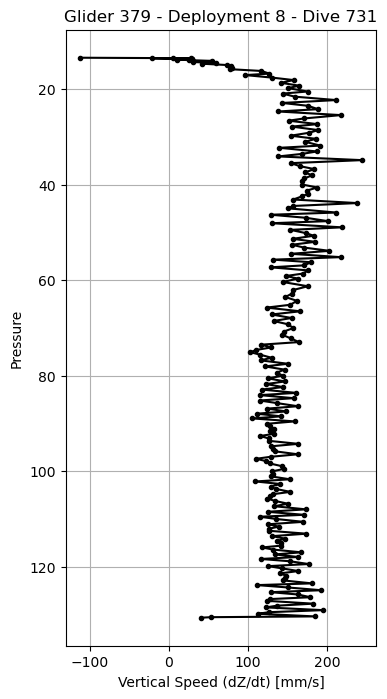

In [50]:
# Calculate the dZ/dt
dZ = dive731['ctd_pressure'].diff(dim='time')
dt = dive731['time'].diff(dim='time').astype(float)/1E9
dZdt = dZ/dt

# Plot the results
fig, ax = plt.subplots(figsize=(4, 8))
ax.plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
ax.set_ylabel('Pressure')
ax.set_xlabel('Vertical Speed (dZ/dt) [mm/s]')
ax.invert_yaxis()
ax.grid()
ax.set_title('Glider 379 - Deployment 8 - Dive 731')
# ax[3].plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
# ax[3].grid()
# ax[3].set_xlabel('Vertical Speed (dZ/dt) [mm/s]')


In [52]:
fig.savefig("../results/figures/GL379.deployment0008.dive731.dZdt.png", facecolor='white', transparent=False, bbox_inches='tight')

In [54]:
# Grab the segment in which dive 731 is a member of
dive731['lat']

<xarray.DataArray 'lat' (time: 221)> Size: 2kB
array([40.0978126 , 40.09781714, 40.0978206 , 40.09782347, 40.09782973,
       40.09783447, 40.09783771, 40.09784114, 40.09784542, 40.09785174,
       40.09785436, 40.09785786, 40.09786316, 40.09786809, 40.09787082,
       40.09787449, 40.09788051, 40.0978841 , 40.09788769, 40.09789042,
       40.09789584, 40.09790093, 40.09790438, 40.09790733, 40.09791392,
       40.09791802, 40.09792104, 40.09792466, 40.09792764, 40.09793477,
       40.09793778, 40.09794152, 40.09794675, 40.09795169, 40.09795483,
       40.09795795, 40.09796192, 40.09796733, 40.09797161, 40.0979746 ,
       40.0979794 , 40.09798464, 40.09798823, 40.09799138, 40.09799457,
       40.0980009 , 40.09800508, 40.09800873, 40.09801144, 40.09801492,
       40.09802059, 40.09802518, 40.09802857, 40.09803305, 40.09803903,
       40.09804194, 40.09804525, 40.09804811, 40.09805486, 40.09805878,
       40.09806208, 40.09806593, 40.0980722 , 40.0980759 , 40.09807868,
       40.09808214, 40.09808658, 40.09809255, 40.09809572, 40.09809932,
       40.09810551, 40.09810895, 40.09811247, 40.09811614, 40.09812096,
       40.09812464, 40.09812967, 40.09813384, 40.09813817, 40.09814125,
       40.09814428, 40.09815117, 40.09815455, 40.09815802, 40.09816065,
       40.09816454, 40.09817019, 40.09817399, 40.09817751, 40.09818207,
       40.09818715, 40.09819156, 40.09819609, 40.09820299, 40.09820855,
       40.098213  , 40.09822125, 40.09822604, 40.09823028, 40.09823662,
...
       40.09837576, 40.09838035, 40.09838396, 40.09838758, 40.09839407,
       40.09839873, 40.09840231, 40.09840781, 40.09841328, 40.09841704,
       40.09842053, 40.09842543, 40.09843153, 40.09843509, 40.09843923,
       40.09844598, 40.09844968, 40.09845318, 40.09845676, 40.09846314,
       40.09846753, 40.09847095, 40.0984765 , 40.09848199, 40.09848539,
       40.0984888 , 40.09849313, 40.09849957, 40.09850305, 40.09850657,
       40.09851345, 40.09851746, 40.09852105, 40.09852454, 40.09853028,
       40.09853541, 40.09853914, 40.09854373, 40.09855002, 40.09855329,
       40.09855689, 40.09856011, 40.09856642, 40.09857049, 40.0985738 ,
       40.09857875, 40.09858447, 40.09858774, 40.09859139, 40.09859473,
       40.09860096, 40.09860476, 40.09860781, 40.0986127 , 40.09861834,
       40.09862142, 40.09862449, 40.09862753, 40.09863307, 40.09863809,
       40.09864107, 40.09864408, 40.09865024, 40.09865398, 40.09865696,
       40.09866006, 40.09866299, 40.09866848, 40.09867291, 40.09867575,
       40.09867863, 40.09868175, 40.09868691, 40.09869154, 40.09869463,
       40.09869762, 40.09870338, 40.09870736, 40.09871045, 40.09871332,
       40.09871628, 40.09872113, 40.09872555, 40.0987281 , 40.09873096,
       40.09873537, 40.09874011, 40.09874302, 40.09874583, 40.09874946,
       40.09875452, 40.09875748, 40.09875987, 40.09876253, 40.09876782,
       40.09877147])
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes:
    comment:        Interpolated GPS latitude in decimal degrees.
    standard_name:  latitude
    long_name:      Interpolated GPS Latitude
    units:          degree_north
    precision:      4
    axis:           Y

In [93]:
#subset = glider.sel(time=slice('20-10-2019','25-10-2019')).load()
subset = glider.where((glider.profile_id >= 638) & (glider.profile_id <= 782), drop=True)
subset

<xarray.Dataset> Size: 153MB
Dimensions:                                    (time: 32843, bin: 30)
Coordinates:
    lon                                        (time) float64 263kB -70.37 .....
    depth                                      (time) float64 263kB 0.0 ... 0.0
    lat                                        (time) float64 263kB 40.07 ......
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 263kB 20...
Data variables: (12/70)
    corrected_echo_intensity_beam4             (time, bin) float64 8MB 83.57 ...
    num_cells                                  (time) float32 131kB 30.0 ... ...
    ensemble_number                            (time) float32 131kB 1.0 ... 3...
    transducer_depth                           (time) float32 131kB 6.0 ... 1...
    corrected_echo_intensity_beam3             (time, bin) float64 8MB 92.72 ...
    corrected_echo_intensity_beam2             (time, bin) float64 8MB 85.4 ....
    ...                                         ...
    vendor_qc_flag                             (time, bin) float64 8MB 1.0 .....
    waypoint_lat                               (time) float64 263kB 39.83 ......
    waypoint_lon                               (time) float64 263kB -71.17 .....
    bottom_track_eastward_velocity             (time) float32 131kB nan ... 4...
    bottom_track_northward_velocity            (time) float32 131kB nan ... 1...
    speed_over_ground                          (time) float32 131kB nan ... 4...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [100]:
# Calculate the segment mean bottom-track velocities and their speed-over-ground
# First, need to segment the data into a regularized pressure grid
step = 2
pres = np.arange(0, 200+step, step)

# Take the means and standard deviations
group = subset[['bottom_track_eastward_velocity','bottom_track_northward_velocity','speed_over_ground','ctd_pressure']].groupby_bins(group='ctd_pressure', bins=pres)
avg = group.mean(skipna=True)
std = group.std(skipna=True)
count = group.count()


/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_im

In [103]:
count

<xarray.Dataset> Size: 4kB
Dimensions:                          (ctd_pressure_bins: 100)
Coordinates:
  * ctd_pressure_bins                (ctd_pressure_bins) object 800B (0, 2] ....
Data variables:
    bottom_track_eastward_velocity   (ctd_pressure_bins) float64 800B 1.0 ......
    bottom_track_northward_velocity  (ctd_pressure_bins) float64 800B 1.0 ......
    speed_over_ground                (ctd_pressure_bins) float64 800B 1.0 ......
    ctd_pressure                     (ctd_pressure_bins) float64 800B 694.0 ....
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

Text(0.5, 0.92, 'Glider 379 - Deployment 8 - North Segment')

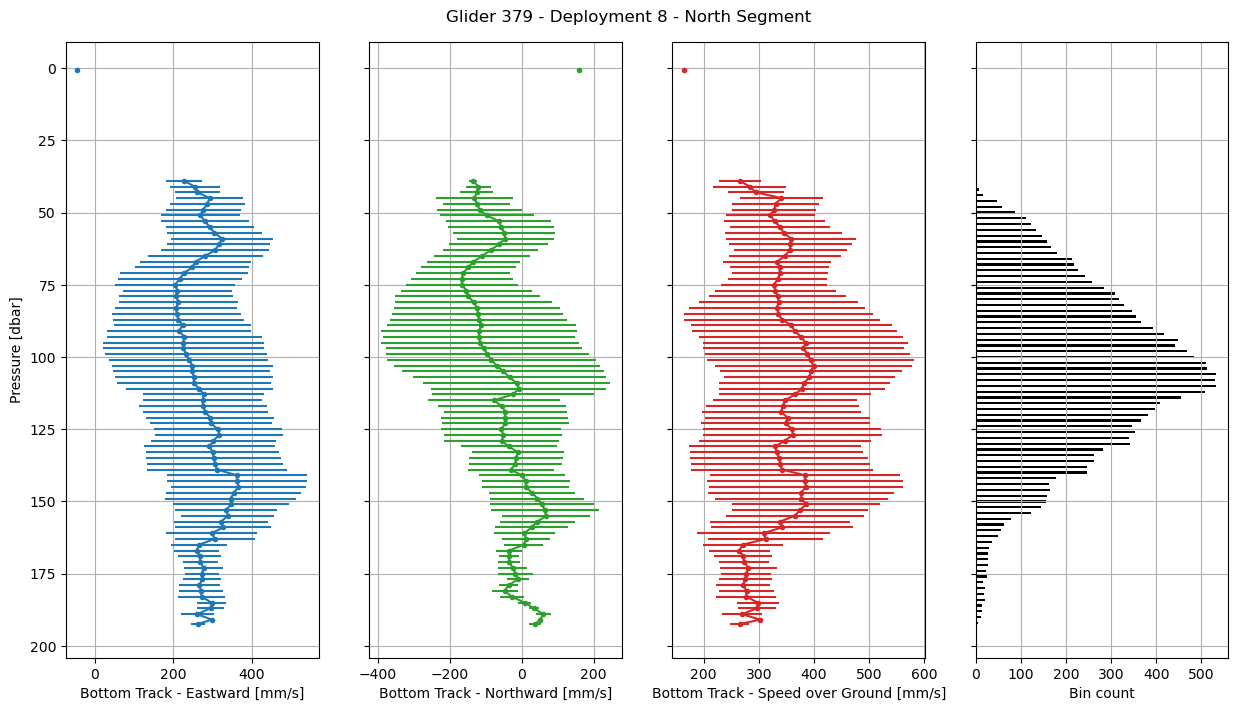

In [119]:
# Plot the profiles
fig, ax = plt.subplots(nrows=1, ncols = 4, figsize=(15, 8), sharey=True)

ax[0].errorbar(avg['bottom_track_eastward_velocity'], avg['ctd_pressure'], xerr=std['bottom_track_eastward_velocity'], marker='.')
ax[0].grid()
ax[0].set_xlabel('Bottom Track - Eastward [mm/s]')
ax[0].set_ylabel('Pressure [dbar]')
ax[0].invert_yaxis()

ax[1].errorbar(avg['bottom_track_northward_velocity'], avg['ctd_pressure'], xerr=std['bottom_track_northward_velocity'], marker='.', color='tab:green')
ax[1].grid()
ax[1].set_xlabel('Bottom Track - Northward [mm/s]')
#ax[1].set_title('Glider 379 - Deployment 8 - North Segment')

ax[2].errorbar(avg['speed_over_ground'], avg['ctd_pressure'], xerr=std['speed_over_ground'], marker='.', color='tab:red')
ax[2].grid()
ax[2].set_xlabel('Bottom Track - Speed over Ground [mm/s]')

ax[3].barh(pres[1:], count['speed_over_ground'], color='black')
ax[3].set_xlabel('Bin count')
ax[3].grid()

fig.suptitle('Glider 379 - Deployment 8 - North Segment', y=0.92)

In [120]:
fig.savefig("../results/figures/GL379.deployment0008.north_segment.bottom_track.png", facecolor='white', transparent=False, bbox_inches='tight')

### Remove Bottom-Track from Velocity Profiles

In [127]:
# First, need to interpolate the bottom_track values on a given profile to 
dive731['ctd_pressure']

<xarray.DataArray 'ctd_pressure' (time: 221)> Size: 2kB
array([ 13.76012245,  13.42555735,  13.53562929,  13.62616195,
        13.54066427,  13.56359581,  13.67240932,  13.78589207,
        13.82443111,  13.92843958,  14.09277362,  14.21395909,
        14.3140454 ,  14.55057741,  14.68058299,  14.95376896,
        15.22295522,  15.50986031,  15.83012633,  16.19561444,
        16.75388282,  17.06002136,  17.58082449,  18.10169424,
        18.67867888,  19.27626602,  19.78445545,  20.49572686,
        20.93058082,  21.57606141,  22.28797716,  22.89196454,
        23.49094359,  24.1934208 ,  24.67889491,  25.43669992,
        26.1462691 ,  26.60430338,  27.32462616,  27.84473733,
        28.57253823,  29.12534627,  29.74499302,  30.40055419,
        31.01367012,  31.81870145,  32.27883982,  33.04418134,
        33.55330002,  34.0853994 ,  34.85970778,  35.49178448,
        36.1182578 ,  36.73724412,  37.43816233,  38.03141635,
        38.69470955,  39.23201315,  39.96856052,  40.58880586,
        41.23445707,  41.8474146 ,  42.45170674,  43.1032732 ,
        43.84721059,  44.45618655,  44.94783277,  45.82961656,
        46.28733566,  46.92930687,  47.62581899,  48.06418706,
        48.92475454,  49.45735797,  50.137234  ,  50.68764496,
        51.32909769,  51.95897716,  52.56837406,  53.15806467,
...
        93.10053086,  93.60398705,  94.23999948,  94.76011722,
        95.29284875,  95.80502649,  96.42676931,  96.94841379,
        97.36833328,  97.84745087,  98.35384724,  98.93735627,
        99.49918646, 100.02298761, 100.54066576, 101.06468747,
       101.65759546, 102.1145839 , 102.64580086, 103.18016123,
       103.67564244, 104.29430361, 104.77062911, 105.24070871,
       105.70220766, 106.20197771, 106.77007461, 107.29771432,
       107.94970445, 108.46055585, 109.09314767, 109.4949542 ,
       109.97082756, 110.56510839, 111.06955396, 111.56854891,
       112.00712823, 112.44296945, 113.043865  , 113.55923124,
       114.09457865, 114.55186453, 115.03092529, 115.53970787,
       115.92644986, 116.36565037, 116.94644388, 117.38673028,
       117.91975689, 118.3355637 , 118.82418634, 119.39725903,
       119.83657325, 120.30207669, 120.86647327, 121.35200663,
       121.85156466, 122.32855953, 122.81822838, 123.4468113 ,
       123.80505162, 124.30618953, 124.87908735, 125.28831774,
       125.7721266 , 126.34551985, 126.7345828 , 127.09634837,
       127.69005803, 128.11995015, 128.47369891, 129.04781939,
       129.4714282 , 129.79009499, 130.3587109 , 130.51916496,
       130.63319962])
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes: (12/25)
    _ChunkSizes:            350
    accuracy:               0.01
    actual_range:           [-4.0000e-02  9.7106e+02]
    ancillary_variables:      qartod_pressure_flat_line_flag qartod_pressure_...
    axis:                   Z
    bytes:                  4
    ...                     ...
    resolution:             0.01
    source_sensor:          sci_water_pressure
    standard_name:          sea_water_pressure
    units:                  dbar
    valid_max:              2000.0
    valid_min:              0.0

In [128]:
def remove_bottom_track(glider, bottom_track):
    """Remove the bottom track from the glider DVL water velocities"""
    # Adjust the eastward velocities
    east_bottom_track = bottom_track['bt_eastward_velocity'] / 1000
    eastward_velocity = glider['eastward_seawater_velocity'] - east_bottom_track

    # Adjust the nortward velocities
    north_bottom_track = bottom_track['bt_northward_velocity'] / 1000
    northward_velocity = glider['northward_seawater_velocity'] - north_bottom_track

    # Add the results into the glider dataset
    glider['corrected_eastward_velocity'] = eastward_velocity
    glider['corrected_eastward_velocity'].attrs = {
        'standard_name': 'eastward_seawater_velocity',
        'long_name': 'Motion-Corrected Eastward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Eastward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the eastward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'eastward_seawater_velocity bt_eastward_velocity'
    }

    glider['corrected_northward_velocity'] = northward_velocity
    glider['corrected_northward_velocity'].attrs = {
        'standard_name': 'northward_seawater_velocity',
        'long_name': 'Motion-Corrected Northward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Northward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the northward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'northward_seawater_velocity bt_northward_velocity'
    }

    return glider

In [129]:
adj_dive731 = remove_bottom_track(dive731, bottom_track)

In [130]:
adj_dive731

<xarray.Dataset> Size: 1MB
Dimensions:                                    (time: 221, bin: 30)
Coordinates:
    lon                                        (time) float64 2kB -70.88 ... ...
    depth                                      (time) float64 2kB 0.0 ... 0.0
    lat                                        (time) float64 2kB 40.1 ... 40.1
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 2kB 2019...
Data variables: (12/71)
    corrected_echo_intensity_beam4             (time, bin) float64 53kB 50.63...
    num_cells                                  (time) float32 884B 30.0 ... 30.0
    ensemble_number                            (time) float32 884B 1.0 ... 221.0
    transducer_depth                           (time) float32 884B 135.0 ... ...
    corrected_echo_intensity_beam3             (time, bin) float64 53kB 62.22...
    corrected_echo_intensity_beam2             (time, bin) float64 53kB 58.56...
    ...                                         ...
    waypoint_lat                               (time) float64 2kB 39.83 ... 3...
    waypoint_lon                               (time) float64 2kB -71.17 ... ...
    bottom_track_eastward_velocity             (time) float32 884B nan ... 200.0
    bottom_track_northward_velocity            (time) float32 884B nan ... -1...
    corrected_eastward_velocity                (time, bin) float64 53kB nan ....
    corrected_northward_velocity               (time, bin) float64 53kB nan ....
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [131]:
adj_dive731['corrected_eastward_velocity']

<xarray.DataArray 'corrected_eastward_velocity' (time: 221, bin: 30)> Size: 53kB
array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [0.09107563, 0.07148715, 0.0508773 , ...,        nan,        nan,
               nan],
       [0.04266983, 0.03408418, 0.05869642, ...,        nan,        nan,
               nan],
       [0.04720986, 0.07015407, 0.11868697, ...,        nan,        nan,
               nan]], shape=(221, 30))
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * bin      (bin) int32 120B 0 1 2 3 4 5 6 7 8 9 ... 21 22 23 24 25 26 27 28 29
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes:
    standard_name:        eastward_seawater_velocity
    long_name:            Motion-Corrected Eastward Seawater Velocity
    units:                m s-1
    comment:              Eastward seawater velocity component in Earth coord...
    ancillary_variables:  eastward_seawater_velocity bt_eastward_velocity

In [1]:
# Load the datasets

In [16]:
import os, sys, re, ast
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
glider = xr.open_dataset("../data/processed/CP05MOAS-GL379.deployment0008.merged.nc")
glider

<xarray.Dataset> Size: 3GB
Dimensions:                                    (time: 604054, bin: 30)
Coordinates:
    lon                                        (time) float64 5MB ...
    depth                                      (time) float64 5MB ...
    lat                                        (time) float64 5MB ...
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 5MB 2019...
Data variables: (12/67)
    corrected_echo_intensity_beam4             (time, bin) float64 145MB ...
    num_cells                                  (time) float32 2MB ...
    ensemble_number                            (time) float32 2MB ...
    transducer_depth                           (time) float32 2MB ...
    corrected_echo_intensity_beam3             (time, bin) float64 145MB ...
    corrected_echo_intensity_beam2             (time, bin) float64 145MB ...
    ...                                         ...
    glider_precise_lon                         (time) float64 5MB ...
    glider_roll                                (time) float64 5MB ...
    profile_id                                 (time) int64 5MB ...
    vendor_qc_flag                             (time, bin) int64 145MB ...
    waypoint_lat                               (time) float64 5MB ...
    waypoint_lon                               (time) float64 5MB ...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [5]:
bottom_track = xr.open_dataset("../data/raw//CP05MOAS-GL379-01-ADCPAM000.deployment0008.adcp_bottom_track.nc")
bottom_track.load()

<xarray.Dataset> Size: 167MB
Dimensions:                          (time: 604054)
Coordinates:
    lon                              (time) float64 5MB -70.6 -70.6 ... -70.53
    depth                            (time) float64 5MB 0.2459 0.306 ... 102.2
  * time                             (time) datetime64[ns] 5MB 2019-09-27T12:...
    lat                              (time) float64 5MB 40.05 40.05 ... 40.12
Data variables: (12/51)
    bt_beam4_ref_intensity           (time) float32 2MB 67.0 66.0 ... nan nan
    bt_beam1_percent_good            (time) float32 2MB nan nan nan ... nan nan
    bt_beam2_rssi_amplitude          (time) float32 2MB nan nan ... 158.0 162.0
    bt_beam4_ref_correlation         (time) float32 2MB 109.0 104.0 ... nan nan
    bt_beam2_correlation             (time) float32 2MB nan nan ... 255.0 255.0
    bt_gain                          (time) float32 2MB nan 15.0 ... 15.0 15.0
    ...                               ...
    bt_upward_ref_layer_velocity     (time) float32 2MB -292.0 -81.0 ... nan nan
    bt_beam3_correlation             (time) float32 2MB nan nan ... 255.0 255.0
    bt_beam3_range                   (time) float64 5MB nan nan ... 2.21e+03
    bt_beam2_ref_intensity           (time) float32 2MB 71.0 72.0 ... nan nan
    bt_beam2_eval_amp                (time) float32 2MB nan nan ... 56.0 55.0
    bt_ref_layer_near                (time) float32 2MB 80.0 80.0 ... 0.0 0.0
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_bottom_track_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -71.18116628263888
    geospatial_lon_max:                 -70.30236914112658
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [7]:
def remove_bottom_track(glider, bottom_track):
    """Remove the bottom track from the glider DVL water velocities"""
    # Adjust the eastward velocities
    east_bottom_track = bottom_track['bt_eastward_velocity'] / 1000
    eastward_velocity = glider['eastward_seawater_velocity'] - east_bottom_track

    # Adjust the nortward velocities
    north_bottom_track = bottom_track['bt_northward_velocity'] / 1000
    northward_velocity = glider['northward_seawater_velocity'] - north_bottom_track

    # Add the results into the glider dataset
    glider['corrected_eastward_velocity'] = eastward_velocity
    glider['corrected_eastward_velocity'].attrs = {
        'standard_name': 'eastward_seawater_velocity',
        'long_name': 'Motion-Corrected Eastward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Eastward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the eastward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'eastward_seawater_velocity bt_eastward_velocity'
    }

    glider['corrected_northward_velocity'] = northward_velocity
    glider['corrected_northward_velocity'].attrs = {
        'standard_name': 'northward_seawater_velocity',
        'long_name': 'Motion-Corrected Northward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Northward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the northward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'northward_seawater_velocity bt_northward_velocity'
    }

    return glider
    

In [9]:
# Add the eastward and northward bottom track velocities to the glider dataset
glider['bottom_track_eastward_velocity'] = bottom_track['bt_eastward_velocity']
glider['bottom_track_northward_velocity'] = bottom_track['bt_northward_velocity']

### Bottom-Track Statistics
Next, calculate some of the statistics for the bottom track data

##### Glider 379 - Deployment 8 - Dive 731

In [11]:
dive731 = glider.where(glider['profile_id'] == 731, drop=True)
dive731

<xarray.Dataset> Size: 1MB
Dimensions:                                    (time: 221, bin: 30)
Coordinates:
    lon                                        (time) float64 2kB -70.88 ... ...
    depth                                      (time) float64 2kB 0.0 ... 0.0
    lat                                        (time) float64 2kB 40.1 ... 40.1
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 2kB 2019...
Data variables: (12/69)
    corrected_echo_intensity_beam4             (time, bin) float64 53kB 50.63...
    num_cells                                  (time) float32 884B 30.0 ... 30.0
    ensemble_number                            (time) float32 884B 1.0 ... 221.0
    transducer_depth                           (time) float32 884B 135.0 ... ...
    corrected_echo_intensity_beam3             (time, bin) float64 53kB 62.22...
    corrected_echo_intensity_beam2             (time, bin) float64 53kB 58.56...
    ...                                         ...
    profile_id                                 (time) float64 2kB 731.0 ... 7...
    vendor_qc_flag                             (time, bin) float64 53kB 1.0 ....
    waypoint_lat                               (time) float64 2kB 39.83 ... 3...
    waypoint_lon                               (time) float64 2kB -71.17 ... ...
    bottom_track_eastward_velocity             (time) float32 884B nan ... 200.0
    bottom_track_northward_velocity            (time) float32 884B nan ... -1...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [13]:
# Calculate the mean northward and eastward bottom_track velocitys
eastward_velocity = dive731['bottom_track_eastward_velocity'].mean(dim='time', skipna=True).values
northward_velocity = dive731['bottom_track_northward_velocity'].mean(dim='time', skipna=True).values
eastward_velocity, northward_velocity

(array(180.6378, dtype=float32), array(-178.70079, dtype=float32))

In [14]:
eastward_velocity = dive731['bottom_track_eastward_velocity'].std(dim='time', skipna=True).values
northward_velocity = dive731['bottom_track_northward_velocity'].std(dim='time', skipna=True).values
eastward_velocity, northward_velocity

(array(103.54387, dtype=float32), array(79.082664, dtype=float32))

In [92]:
sog = np.sqrt(dive731['bottom_track_eastward_velocity']**2 + dive731['bottom_track_northward_velocity']**2)
glider['speed_over_ground'] = np.sqrt(glider['bottom_track_eastward_velocity']**2 + glider['bottom_track_northward_velocity']**2)

Text(0.5, 0, 'Bottom Track - Speed over Ground [mm/s]')

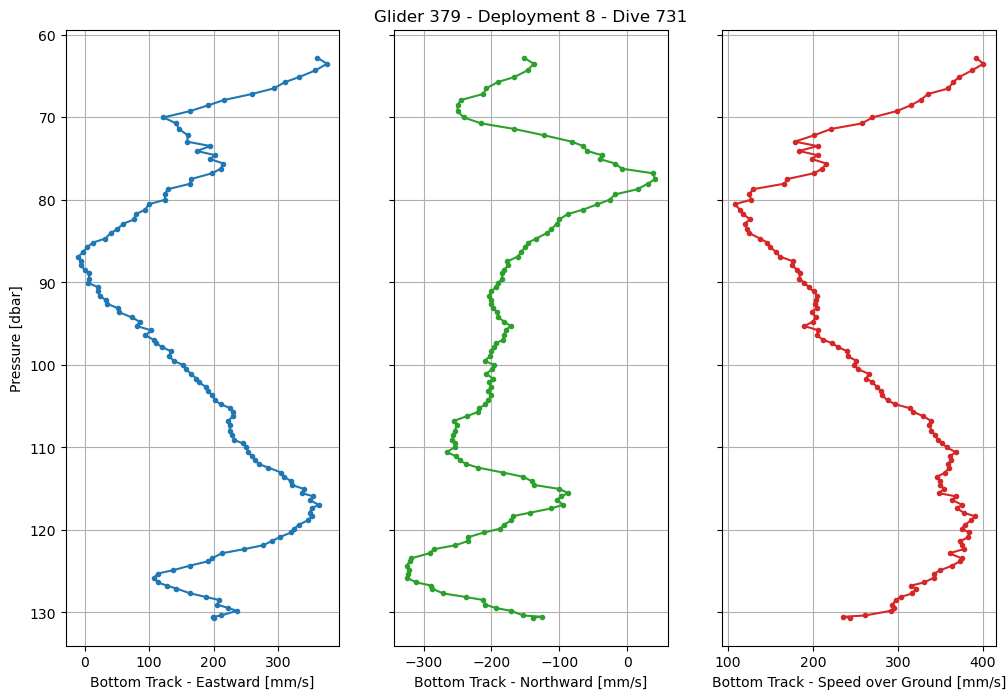

In [48]:
# Plot the profiles
fig, ax = plt.subplots(nrows=1, ncols = 3, figsize=(12, 8), sharey=True)

ax[0].plot(dive731['bottom_track_eastward_velocity'], dive731['ctd_pressure'], marker='.')
ax[0].grid()
ax[0].set_xlabel('Bottom Track - Eastward [mm/s]')
ax[0].set_ylabel('Pressure [dbar]')
ax[0].invert_yaxis()

ax[1].plot(dive731['bottom_track_northward_velocity'], dive731['ctd_pressure'], marker='.', color='tab:green')
ax[1].grid()
ax[1].set_xlabel('Bottom Track - Northward [mm/s]')
ax[1].set_title('Glider 379 - Deployment 8 - Dive 731')

ax[2].plot(sog, dive731['ctd_pressure'], marker='.', color='tab:red')
ax[2].grid()
ax[2].set_xlabel('Bottom Track - Speed over Ground [mm/s]')

# ax[3].plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
# ax[3].grid()
# ax[3].set_xlabel('Vertical Speed (dZ/dt) [mm/s]')


In [49]:
fig.savefig("../results/figures/GL379.deployment0008.dive731.bottom_track.png", facecolor='white', transparent=False, bbox_inches='tight')

Text(0.5, 1.0, 'Glider 379 - Deployment 8 - Dive 731')

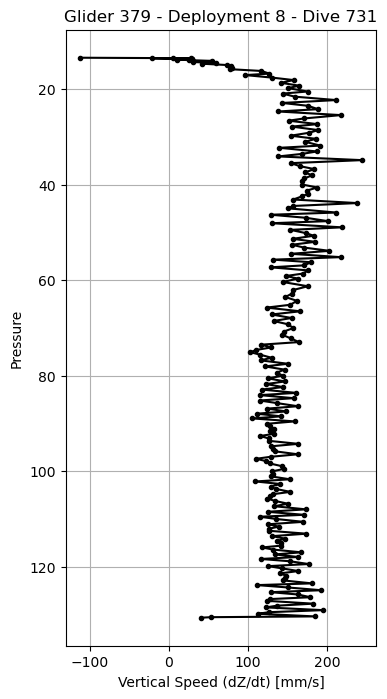

In [50]:
# Calculate the dZ/dt
dZ = dive731['ctd_pressure'].diff(dim='time')
dt = dive731['time'].diff(dim='time').astype(float)/1E9
dZdt = dZ/dt

# Plot the results
fig, ax = plt.subplots(figsize=(4, 8))
ax.plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
ax.set_ylabel('Pressure')
ax.set_xlabel('Vertical Speed (dZ/dt) [mm/s]')
ax.invert_yaxis()
ax.grid()
ax.set_title('Glider 379 - Deployment 8 - Dive 731')
# ax[3].plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
# ax[3].grid()
# ax[3].set_xlabel('Vertical Speed (dZ/dt) [mm/s]')


In [52]:
fig.savefig("../results/figures/GL379.deployment0008.dive731.dZdt.png", facecolor='white', transparent=False, bbox_inches='tight')

In [54]:
# Grab the segment in which dive 731 is a member of
dive731['lat']

<xarray.DataArray 'lat' (time: 221)> Size: 2kB
array([40.0978126 , 40.09781714, 40.0978206 , 40.09782347, 40.09782973,
       40.09783447, 40.09783771, 40.09784114, 40.09784542, 40.09785174,
       40.09785436, 40.09785786, 40.09786316, 40.09786809, 40.09787082,
       40.09787449, 40.09788051, 40.0978841 , 40.09788769, 40.09789042,
       40.09789584, 40.09790093, 40.09790438, 40.09790733, 40.09791392,
       40.09791802, 40.09792104, 40.09792466, 40.09792764, 40.09793477,
       40.09793778, 40.09794152, 40.09794675, 40.09795169, 40.09795483,
       40.09795795, 40.09796192, 40.09796733, 40.09797161, 40.0979746 ,
       40.0979794 , 40.09798464, 40.09798823, 40.09799138, 40.09799457,
       40.0980009 , 40.09800508, 40.09800873, 40.09801144, 40.09801492,
       40.09802059, 40.09802518, 40.09802857, 40.09803305, 40.09803903,
       40.09804194, 40.09804525, 40.09804811, 40.09805486, 40.09805878,
       40.09806208, 40.09806593, 40.0980722 , 40.0980759 , 40.09807868,
       40.09808214, 40.09808658, 40.09809255, 40.09809572, 40.09809932,
       40.09810551, 40.09810895, 40.09811247, 40.09811614, 40.09812096,
       40.09812464, 40.09812967, 40.09813384, 40.09813817, 40.09814125,
       40.09814428, 40.09815117, 40.09815455, 40.09815802, 40.09816065,
       40.09816454, 40.09817019, 40.09817399, 40.09817751, 40.09818207,
       40.09818715, 40.09819156, 40.09819609, 40.09820299, 40.09820855,
       40.098213  , 40.09822125, 40.09822604, 40.09823028, 40.09823662,
...
       40.09837576, 40.09838035, 40.09838396, 40.09838758, 40.09839407,
       40.09839873, 40.09840231, 40.09840781, 40.09841328, 40.09841704,
       40.09842053, 40.09842543, 40.09843153, 40.09843509, 40.09843923,
       40.09844598, 40.09844968, 40.09845318, 40.09845676, 40.09846314,
       40.09846753, 40.09847095, 40.0984765 , 40.09848199, 40.09848539,
       40.0984888 , 40.09849313, 40.09849957, 40.09850305, 40.09850657,
       40.09851345, 40.09851746, 40.09852105, 40.09852454, 40.09853028,
       40.09853541, 40.09853914, 40.09854373, 40.09855002, 40.09855329,
       40.09855689, 40.09856011, 40.09856642, 40.09857049, 40.0985738 ,
       40.09857875, 40.09858447, 40.09858774, 40.09859139, 40.09859473,
       40.09860096, 40.09860476, 40.09860781, 40.0986127 , 40.09861834,
       40.09862142, 40.09862449, 40.09862753, 40.09863307, 40.09863809,
       40.09864107, 40.09864408, 40.09865024, 40.09865398, 40.09865696,
       40.09866006, 40.09866299, 40.09866848, 40.09867291, 40.09867575,
       40.09867863, 40.09868175, 40.09868691, 40.09869154, 40.09869463,
       40.09869762, 40.09870338, 40.09870736, 40.09871045, 40.09871332,
       40.09871628, 40.09872113, 40.09872555, 40.0987281 , 40.09873096,
       40.09873537, 40.09874011, 40.09874302, 40.09874583, 40.09874946,
       40.09875452, 40.09875748, 40.09875987, 40.09876253, 40.09876782,
       40.09877147])
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes:
    comment:        Interpolated GPS latitude in decimal degrees.
    standard_name:  latitude
    long_name:      Interpolated GPS Latitude
    units:          degree_north
    precision:      4
    axis:           Y

In [93]:
#subset = glider.sel(time=slice('20-10-2019','25-10-2019')).load()
subset = glider.where((glider.profile_id >= 638) & (glider.profile_id <= 782), drop=True)
subset

<xarray.Dataset> Size: 153MB
Dimensions:                                    (time: 32843, bin: 30)
Coordinates:
    lon                                        (time) float64 263kB -70.37 .....
    depth                                      (time) float64 263kB 0.0 ... 0.0
    lat                                        (time) float64 263kB 40.07 ......
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 263kB 20...
Data variables: (12/70)
    corrected_echo_intensity_beam4             (time, bin) float64 8MB 83.57 ...
    num_cells                                  (time) float32 131kB 30.0 ... ...
    ensemble_number                            (time) float32 131kB 1.0 ... 3...
    transducer_depth                           (time) float32 131kB 6.0 ... 1...
    corrected_echo_intensity_beam3             (time, bin) float64 8MB 92.72 ...
    corrected_echo_intensity_beam2             (time, bin) float64 8MB 85.4 ....
    ...                                         ...
    vendor_qc_flag                             (time, bin) float64 8MB 1.0 .....
    waypoint_lat                               (time) float64 263kB 39.83 ......
    waypoint_lon                               (time) float64 263kB -71.17 .....
    bottom_track_eastward_velocity             (time) float32 131kB nan ... 4...
    bottom_track_northward_velocity            (time) float32 131kB nan ... 1...
    speed_over_ground                          (time) float32 131kB nan ... 4...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [100]:
# Calculate the segment mean bottom-track velocities and their speed-over-ground
# First, need to segment the data into a regularized pressure grid
step = 2
pres = np.arange(0, 200+step, step)

# Take the means and standard deviations
group = subset[['bottom_track_eastward_velocity','bottom_track_northward_velocity','speed_over_ground','ctd_pressure']].groupby_bins(group='ctd_pressure', bins=pres)
avg = group.mean(skipna=True)
std = group.std(skipna=True)
count = group.count()


/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_im

In [103]:
count

<xarray.Dataset> Size: 4kB
Dimensions:                          (ctd_pressure_bins: 100)
Coordinates:
  * ctd_pressure_bins                (ctd_pressure_bins) object 800B (0, 2] ....
Data variables:
    bottom_track_eastward_velocity   (ctd_pressure_bins) float64 800B 1.0 ......
    bottom_track_northward_velocity  (ctd_pressure_bins) float64 800B 1.0 ......
    speed_over_ground                (ctd_pressure_bins) float64 800B 1.0 ......
    ctd_pressure                     (ctd_pressure_bins) float64 800B 694.0 ....
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

Text(0.5, 0.92, 'Glider 379 - Deployment 8 - North Segment')

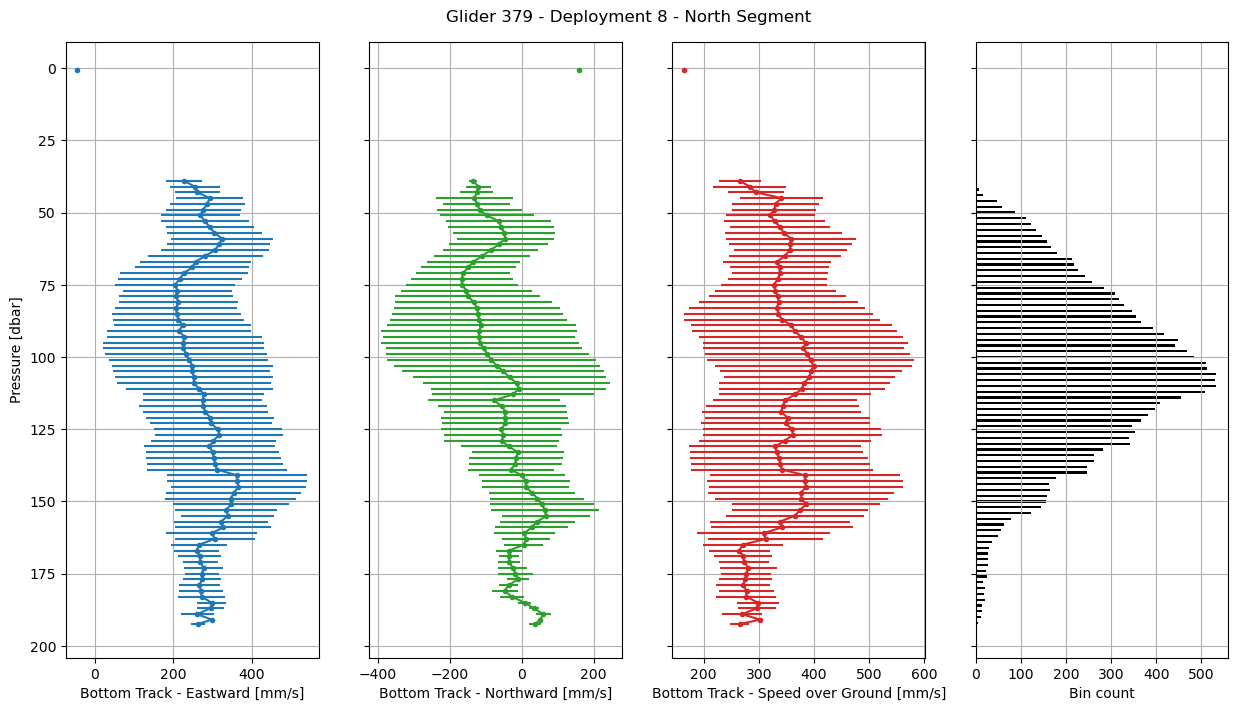

In [119]:
# Plot the profiles
fig, ax = plt.subplots(nrows=1, ncols = 4, figsize=(15, 8), sharey=True)

ax[0].errorbar(avg['bottom_track_eastward_velocity'], avg['ctd_pressure'], xerr=std['bottom_track_eastward_velocity'], marker='.')
ax[0].grid()
ax[0].set_xlabel('Bottom Track - Eastward [mm/s]')
ax[0].set_ylabel('Pressure [dbar]')
ax[0].invert_yaxis()

ax[1].errorbar(avg['bottom_track_northward_velocity'], avg['ctd_pressure'], xerr=std['bottom_track_northward_velocity'], marker='.', color='tab:green')
ax[1].grid()
ax[1].set_xlabel('Bottom Track - Northward [mm/s]')
#ax[1].set_title('Glider 379 - Deployment 8 - North Segment')

ax[2].errorbar(avg['speed_over_ground'], avg['ctd_pressure'], xerr=std['speed_over_ground'], marker='.', color='tab:red')
ax[2].grid()
ax[2].set_xlabel('Bottom Track - Speed over Ground [mm/s]')

ax[3].barh(pres[1:], count['speed_over_ground'], color='black')
ax[3].set_xlabel('Bin count')
ax[3].grid()

fig.suptitle('Glider 379 - Deployment 8 - North Segment', y=0.92)

In [120]:
fig.savefig("../results/figures/GL379.deployment0008.north_segment.bottom_track.png", facecolor='white', transparent=False, bbox_inches='tight')

### Remove Bottom-Track from Velocity Profiles

In [127]:
# First, need to interpolate the bottom_track values on a given profile to 
dive731['ctd_pressure']

<xarray.DataArray 'ctd_pressure' (time: 221)> Size: 2kB
array([ 13.76012245,  13.42555735,  13.53562929,  13.62616195,
        13.54066427,  13.56359581,  13.67240932,  13.78589207,
        13.82443111,  13.92843958,  14.09277362,  14.21395909,
        14.3140454 ,  14.55057741,  14.68058299,  14.95376896,
        15.22295522,  15.50986031,  15.83012633,  16.19561444,
        16.75388282,  17.06002136,  17.58082449,  18.10169424,
        18.67867888,  19.27626602,  19.78445545,  20.49572686,
        20.93058082,  21.57606141,  22.28797716,  22.89196454,
        23.49094359,  24.1934208 ,  24.67889491,  25.43669992,
        26.1462691 ,  26.60430338,  27.32462616,  27.84473733,
        28.57253823,  29.12534627,  29.74499302,  30.40055419,
        31.01367012,  31.81870145,  32.27883982,  33.04418134,
        33.55330002,  34.0853994 ,  34.85970778,  35.49178448,
        36.1182578 ,  36.73724412,  37.43816233,  38.03141635,
        38.69470955,  39.23201315,  39.96856052,  40.58880586,
        41.23445707,  41.8474146 ,  42.45170674,  43.1032732 ,
        43.84721059,  44.45618655,  44.94783277,  45.82961656,
        46.28733566,  46.92930687,  47.62581899,  48.06418706,
        48.92475454,  49.45735797,  50.137234  ,  50.68764496,
        51.32909769,  51.95897716,  52.56837406,  53.15806467,
...
        93.10053086,  93.60398705,  94.23999948,  94.76011722,
        95.29284875,  95.80502649,  96.42676931,  96.94841379,
        97.36833328,  97.84745087,  98.35384724,  98.93735627,
        99.49918646, 100.02298761, 100.54066576, 101.06468747,
       101.65759546, 102.1145839 , 102.64580086, 103.18016123,
       103.67564244, 104.29430361, 104.77062911, 105.24070871,
       105.70220766, 106.20197771, 106.77007461, 107.29771432,
       107.94970445, 108.46055585, 109.09314767, 109.4949542 ,
       109.97082756, 110.56510839, 111.06955396, 111.56854891,
       112.00712823, 112.44296945, 113.043865  , 113.55923124,
       114.09457865, 114.55186453, 115.03092529, 115.53970787,
       115.92644986, 116.36565037, 116.94644388, 117.38673028,
       117.91975689, 118.3355637 , 118.82418634, 119.39725903,
       119.83657325, 120.30207669, 120.86647327, 121.35200663,
       121.85156466, 122.32855953, 122.81822838, 123.4468113 ,
       123.80505162, 124.30618953, 124.87908735, 125.28831774,
       125.7721266 , 126.34551985, 126.7345828 , 127.09634837,
       127.69005803, 128.11995015, 128.47369891, 129.04781939,
       129.4714282 , 129.79009499, 130.3587109 , 130.51916496,
       130.63319962])
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes: (12/25)
    _ChunkSizes:            350
    accuracy:               0.01
    actual_range:           [-4.0000e-02  9.7106e+02]
    ancillary_variables:      qartod_pressure_flat_line_flag qartod_pressure_...
    axis:                   Z
    bytes:                  4
    ...                     ...
    resolution:             0.01
    source_sensor:          sci_water_pressure
    standard_name:          sea_water_pressure
    units:                  dbar
    valid_max:              2000.0
    valid_min:              0.0

In [128]:
def remove_bottom_track(glider, bottom_track):
    """Remove the bottom track from the glider DVL water velocities"""
    # Adjust the eastward velocities
    east_bottom_track = bottom_track['bt_eastward_velocity'] / 1000
    eastward_velocity = glider['eastward_seawater_velocity'] - east_bottom_track

    # Adjust the nortward velocities
    north_bottom_track = bottom_track['bt_northward_velocity'] / 1000
    northward_velocity = glider['northward_seawater_velocity'] - north_bottom_track

    # Add the results into the glider dataset
    glider['corrected_eastward_velocity'] = eastward_velocity
    glider['corrected_eastward_velocity'].attrs = {
        'standard_name': 'eastward_seawater_velocity',
        'long_name': 'Motion-Corrected Eastward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Eastward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the eastward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'eastward_seawater_velocity bt_eastward_velocity'
    }

    glider['corrected_northward_velocity'] = northward_velocity
    glider['corrected_northward_velocity'].attrs = {
        'standard_name': 'northward_seawater_velocity',
        'long_name': 'Motion-Corrected Northward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Northward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the northward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'northward_seawater_velocity bt_northward_velocity'
    }

    return glider

In [129]:
adj_dive731 = remove_bottom_track(dive731, bottom_track)

In [130]:
adj_dive731

<xarray.Dataset> Size: 1MB
Dimensions:                                    (time: 221, bin: 30)
Coordinates:
    lon                                        (time) float64 2kB -70.88 ... ...
    depth                                      (time) float64 2kB 0.0 ... 0.0
    lat                                        (time) float64 2kB 40.1 ... 40.1
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 2kB 2019...
Data variables: (12/71)
    corrected_echo_intensity_beam4             (time, bin) float64 53kB 50.63...
    num_cells                                  (time) float32 884B 30.0 ... 30.0
    ensemble_number                            (time) float32 884B 1.0 ... 221.0
    transducer_depth                           (time) float32 884B 135.0 ... ...
    corrected_echo_intensity_beam3             (time, bin) float64 53kB 62.22...
    corrected_echo_intensity_beam2             (time, bin) float64 53kB 58.56...
    ...                                         ...
    waypoint_lat                               (time) float64 2kB 39.83 ... 3...
    waypoint_lon                               (time) float64 2kB -71.17 ... ...
    bottom_track_eastward_velocity             (time) float32 884B nan ... 200.0
    bottom_track_northward_velocity            (time) float32 884B nan ... -1...
    corrected_eastward_velocity                (time, bin) float64 53kB nan ....
    corrected_northward_velocity               (time, bin) float64 53kB nan ....
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [131]:
adj_dive731['corrected_eastward_velocity']

<xarray.DataArray 'corrected_eastward_velocity' (time: 221, bin: 30)> Size: 53kB
array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [0.09107563, 0.07148715, 0.0508773 , ...,        nan,        nan,
               nan],
       [0.04266983, 0.03408418, 0.05869642, ...,        nan,        nan,
               nan],
       [0.04720986, 0.07015407, 0.11868697, ...,        nan,        nan,
               nan]], shape=(221, 30))
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * bin      (bin) int32 120B 0 1 2 3 4 5 6 7 8 9 ... 21 22 23 24 25 26 27 28 29
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes:
    standard_name:        eastward_seawater_velocity
    long_name:            Motion-Corrected Eastward Seawater Velocity
    units:                m s-1
    comment:              Eastward seawater velocity component in Earth coord...
    ancillary_variables:  eastward_seawater_velocity bt_eastward_velocity

In [1]:
# Load the datasets

In [16]:
import os, sys, re, ast
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
glider = xr.open_dataset("../data/processed/CP05MOAS-GL379.deployment0008.merged.nc")
glider

<xarray.Dataset> Size: 3GB
Dimensions:                                    (time: 604054, bin: 30)
Coordinates:
    lon                                        (time) float64 5MB ...
    depth                                      (time) float64 5MB ...
    lat                                        (time) float64 5MB ...
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 5MB 2019...
Data variables: (12/67)
    corrected_echo_intensity_beam4             (time, bin) float64 145MB ...
    num_cells                                  (time) float32 2MB ...
    ensemble_number                            (time) float32 2MB ...
    transducer_depth                           (time) float32 2MB ...
    corrected_echo_intensity_beam3             (time, bin) float64 145MB ...
    corrected_echo_intensity_beam2             (time, bin) float64 145MB ...
    ...                                         ...
    glider_precise_lon                         (time) float64 5MB ...
    glider_roll                                (time) float64 5MB ...
    profile_id                                 (time) int64 5MB ...
    vendor_qc_flag                             (time, bin) int64 145MB ...
    waypoint_lat                               (time) float64 5MB ...
    waypoint_lon                               (time) float64 5MB ...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [5]:
bottom_track = xr.open_dataset("../data/raw//CP05MOAS-GL379-01-ADCPAM000.deployment0008.adcp_bottom_track.nc")
bottom_track.load()

<xarray.Dataset> Size: 167MB
Dimensions:                          (time: 604054)
Coordinates:
    lon                              (time) float64 5MB -70.6 -70.6 ... -70.53
    depth                            (time) float64 5MB 0.2459 0.306 ... 102.2
  * time                             (time) datetime64[ns] 5MB 2019-09-27T12:...
    lat                              (time) float64 5MB 40.05 40.05 ... 40.12
Data variables: (12/51)
    bt_beam4_ref_intensity           (time) float32 2MB 67.0 66.0 ... nan nan
    bt_beam1_percent_good            (time) float32 2MB nan nan nan ... nan nan
    bt_beam2_rssi_amplitude          (time) float32 2MB nan nan ... 158.0 162.0
    bt_beam4_ref_correlation         (time) float32 2MB 109.0 104.0 ... nan nan
    bt_beam2_correlation             (time) float32 2MB nan nan ... 255.0 255.0
    bt_gain                          (time) float32 2MB nan 15.0 ... 15.0 15.0
    ...                               ...
    bt_upward_ref_layer_velocity     (time) float32 2MB -292.0 -81.0 ... nan nan
    bt_beam3_correlation             (time) float32 2MB nan nan ... 255.0 255.0
    bt_beam3_range                   (time) float64 5MB nan nan ... 2.21e+03
    bt_beam2_ref_intensity           (time) float32 2MB 71.0 72.0 ... nan nan
    bt_beam2_eval_amp                (time) float32 2MB nan nan ... 56.0 55.0
    bt_ref_layer_near                (time) float32 2MB 80.0 80.0 ... 0.0 0.0
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_bottom_track_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -71.18116628263888
    geospatial_lon_max:                 -70.30236914112658
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [7]:
def remove_bottom_track(glider, bottom_track):
    """Remove the bottom track from the glider DVL water velocities"""
    # Adjust the eastward velocities
    east_bottom_track = bottom_track['bt_eastward_velocity'] / 1000
    eastward_velocity = glider['eastward_seawater_velocity'] - east_bottom_track

    # Adjust the nortward velocities
    north_bottom_track = bottom_track['bt_northward_velocity'] / 1000
    northward_velocity = glider['northward_seawater_velocity'] - north_bottom_track

    # Add the results into the glider dataset
    glider['corrected_eastward_velocity'] = eastward_velocity
    glider['corrected_eastward_velocity'].attrs = {
        'standard_name': 'eastward_seawater_velocity',
        'long_name': 'Motion-Corrected Eastward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Eastward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the eastward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'eastward_seawater_velocity bt_eastward_velocity'
    }

    glider['corrected_northward_velocity'] = northward_velocity
    glider['corrected_northward_velocity'].attrs = {
        'standard_name': 'northward_seawater_velocity',
        'long_name': 'Motion-Corrected Northward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Northward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the northward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'northward_seawater_velocity bt_northward_velocity'
    }

    return glider
    

In [9]:
# Add the eastward and northward bottom track velocities to the glider dataset
glider['bottom_track_eastward_velocity'] = bottom_track['bt_eastward_velocity']
glider['bottom_track_northward_velocity'] = bottom_track['bt_northward_velocity']

### Bottom-Track Statistics
Next, calculate some of the statistics for the bottom track data

##### Glider 379 - Deployment 8 - Dive 731

In [11]:
dive731 = glider.where(glider['profile_id'] == 731, drop=True)
dive731

<xarray.Dataset> Size: 1MB
Dimensions:                                    (time: 221, bin: 30)
Coordinates:
    lon                                        (time) float64 2kB -70.88 ... ...
    depth                                      (time) float64 2kB 0.0 ... 0.0
    lat                                        (time) float64 2kB 40.1 ... 40.1
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 2kB 2019...
Data variables: (12/69)
    corrected_echo_intensity_beam4             (time, bin) float64 53kB 50.63...
    num_cells                                  (time) float32 884B 30.0 ... 30.0
    ensemble_number                            (time) float32 884B 1.0 ... 221.0
    transducer_depth                           (time) float32 884B 135.0 ... ...
    corrected_echo_intensity_beam3             (time, bin) float64 53kB 62.22...
    corrected_echo_intensity_beam2             (time, bin) float64 53kB 58.56...
    ...                                         ...
    profile_id                                 (time) float64 2kB 731.0 ... 7...
    vendor_qc_flag                             (time, bin) float64 53kB 1.0 ....
    waypoint_lat                               (time) float64 2kB 39.83 ... 3...
    waypoint_lon                               (time) float64 2kB -71.17 ... ...
    bottom_track_eastward_velocity             (time) float32 884B nan ... 200.0
    bottom_track_northward_velocity            (time) float32 884B nan ... -1...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [13]:
# Calculate the mean northward and eastward bottom_track velocitys
eastward_velocity = dive731['bottom_track_eastward_velocity'].mean(dim='time', skipna=True).values
northward_velocity = dive731['bottom_track_northward_velocity'].mean(dim='time', skipna=True).values
eastward_velocity, northward_velocity

(array(180.6378, dtype=float32), array(-178.70079, dtype=float32))

In [14]:
eastward_velocity = dive731['bottom_track_eastward_velocity'].std(dim='time', skipna=True).values
northward_velocity = dive731['bottom_track_northward_velocity'].std(dim='time', skipna=True).values
eastward_velocity, northward_velocity

(array(103.54387, dtype=float32), array(79.082664, dtype=float32))

In [92]:
sog = np.sqrt(dive731['bottom_track_eastward_velocity']**2 + dive731['bottom_track_northward_velocity']**2)
glider['speed_over_ground'] = np.sqrt(glider['bottom_track_eastward_velocity']**2 + glider['bottom_track_northward_velocity']**2)

Text(0.5, 0, 'Bottom Track - Speed over Ground [mm/s]')

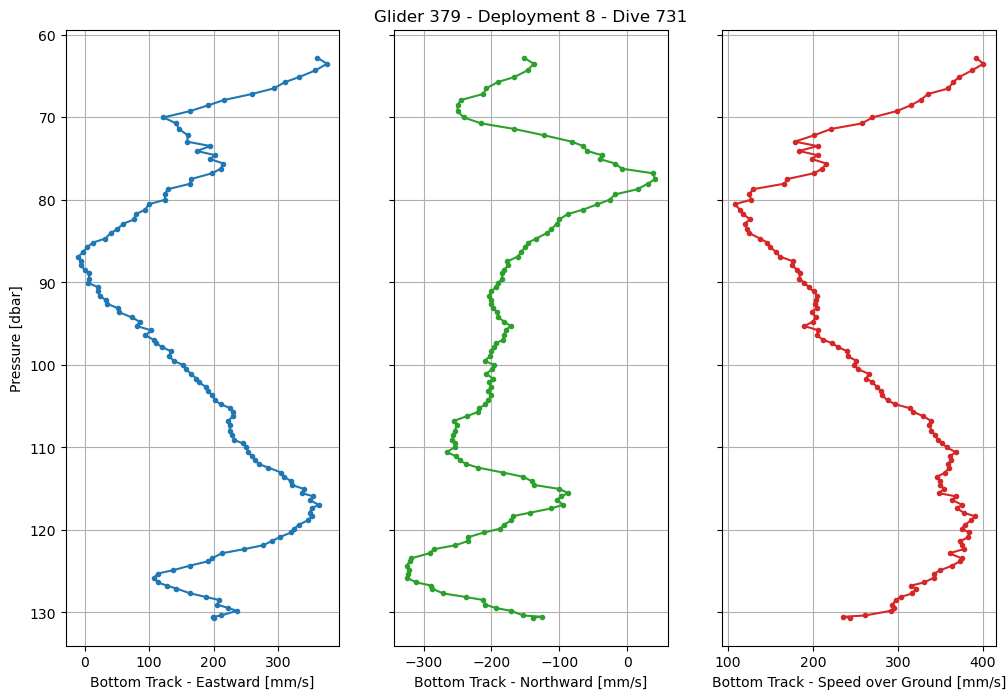

In [48]:
# Plot the profiles
fig, ax = plt.subplots(nrows=1, ncols = 3, figsize=(12, 8), sharey=True)

ax[0].plot(dive731['bottom_track_eastward_velocity'], dive731['ctd_pressure'], marker='.')
ax[0].grid()
ax[0].set_xlabel('Bottom Track - Eastward [mm/s]')
ax[0].set_ylabel('Pressure [dbar]')
ax[0].invert_yaxis()

ax[1].plot(dive731['bottom_track_northward_velocity'], dive731['ctd_pressure'], marker='.', color='tab:green')
ax[1].grid()
ax[1].set_xlabel('Bottom Track - Northward [mm/s]')
ax[1].set_title('Glider 379 - Deployment 8 - Dive 731')

ax[2].plot(sog, dive731['ctd_pressure'], marker='.', color='tab:red')
ax[2].grid()
ax[2].set_xlabel('Bottom Track - Speed over Ground [mm/s]')

# ax[3].plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
# ax[3].grid()
# ax[3].set_xlabel('Vertical Speed (dZ/dt) [mm/s]')


In [49]:
fig.savefig("../results/figures/GL379.deployment0008.dive731.bottom_track.png", facecolor='white', transparent=False, bbox_inches='tight')

Text(0.5, 1.0, 'Glider 379 - Deployment 8 - Dive 731')

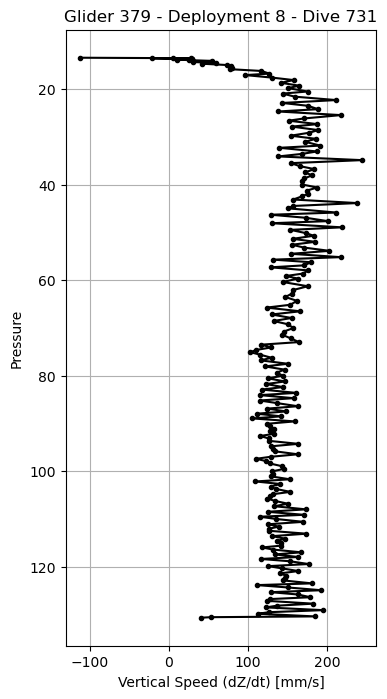

In [50]:
# Calculate the dZ/dt
dZ = dive731['ctd_pressure'].diff(dim='time')
dt = dive731['time'].diff(dim='time').astype(float)/1E9
dZdt = dZ/dt

# Plot the results
fig, ax = plt.subplots(figsize=(4, 8))
ax.plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
ax.set_ylabel('Pressure')
ax.set_xlabel('Vertical Speed (dZ/dt) [mm/s]')
ax.invert_yaxis()
ax.grid()
ax.set_title('Glider 379 - Deployment 8 - Dive 731')
# ax[3].plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
# ax[3].grid()
# ax[3].set_xlabel('Vertical Speed (dZ/dt) [mm/s]')


In [52]:
fig.savefig("../results/figures/GL379.deployment0008.dive731.dZdt.png", facecolor='white', transparent=False, bbox_inches='tight')

In [54]:
# Grab the segment in which dive 731 is a member of
dive731['lat']

<xarray.DataArray 'lat' (time: 221)> Size: 2kB
array([40.0978126 , 40.09781714, 40.0978206 , 40.09782347, 40.09782973,
       40.09783447, 40.09783771, 40.09784114, 40.09784542, 40.09785174,
       40.09785436, 40.09785786, 40.09786316, 40.09786809, 40.09787082,
       40.09787449, 40.09788051, 40.0978841 , 40.09788769, 40.09789042,
       40.09789584, 40.09790093, 40.09790438, 40.09790733, 40.09791392,
       40.09791802, 40.09792104, 40.09792466, 40.09792764, 40.09793477,
       40.09793778, 40.09794152, 40.09794675, 40.09795169, 40.09795483,
       40.09795795, 40.09796192, 40.09796733, 40.09797161, 40.0979746 ,
       40.0979794 , 40.09798464, 40.09798823, 40.09799138, 40.09799457,
       40.0980009 , 40.09800508, 40.09800873, 40.09801144, 40.09801492,
       40.09802059, 40.09802518, 40.09802857, 40.09803305, 40.09803903,
       40.09804194, 40.09804525, 40.09804811, 40.09805486, 40.09805878,
       40.09806208, 40.09806593, 40.0980722 , 40.0980759 , 40.09807868,
       40.09808214, 40.09808658, 40.09809255, 40.09809572, 40.09809932,
       40.09810551, 40.09810895, 40.09811247, 40.09811614, 40.09812096,
       40.09812464, 40.09812967, 40.09813384, 40.09813817, 40.09814125,
       40.09814428, 40.09815117, 40.09815455, 40.09815802, 40.09816065,
       40.09816454, 40.09817019, 40.09817399, 40.09817751, 40.09818207,
       40.09818715, 40.09819156, 40.09819609, 40.09820299, 40.09820855,
       40.098213  , 40.09822125, 40.09822604, 40.09823028, 40.09823662,
...
       40.09837576, 40.09838035, 40.09838396, 40.09838758, 40.09839407,
       40.09839873, 40.09840231, 40.09840781, 40.09841328, 40.09841704,
       40.09842053, 40.09842543, 40.09843153, 40.09843509, 40.09843923,
       40.09844598, 40.09844968, 40.09845318, 40.09845676, 40.09846314,
       40.09846753, 40.09847095, 40.0984765 , 40.09848199, 40.09848539,
       40.0984888 , 40.09849313, 40.09849957, 40.09850305, 40.09850657,
       40.09851345, 40.09851746, 40.09852105, 40.09852454, 40.09853028,
       40.09853541, 40.09853914, 40.09854373, 40.09855002, 40.09855329,
       40.09855689, 40.09856011, 40.09856642, 40.09857049, 40.0985738 ,
       40.09857875, 40.09858447, 40.09858774, 40.09859139, 40.09859473,
       40.09860096, 40.09860476, 40.09860781, 40.0986127 , 40.09861834,
       40.09862142, 40.09862449, 40.09862753, 40.09863307, 40.09863809,
       40.09864107, 40.09864408, 40.09865024, 40.09865398, 40.09865696,
       40.09866006, 40.09866299, 40.09866848, 40.09867291, 40.09867575,
       40.09867863, 40.09868175, 40.09868691, 40.09869154, 40.09869463,
       40.09869762, 40.09870338, 40.09870736, 40.09871045, 40.09871332,
       40.09871628, 40.09872113, 40.09872555, 40.0987281 , 40.09873096,
       40.09873537, 40.09874011, 40.09874302, 40.09874583, 40.09874946,
       40.09875452, 40.09875748, 40.09875987, 40.09876253, 40.09876782,
       40.09877147])
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes:
    comment:        Interpolated GPS latitude in decimal degrees.
    standard_name:  latitude
    long_name:      Interpolated GPS Latitude
    units:          degree_north
    precision:      4
    axis:           Y

In [93]:
#subset = glider.sel(time=slice('20-10-2019','25-10-2019')).load()
subset = glider.where((glider.profile_id >= 638) & (glider.profile_id <= 782), drop=True)
subset

<xarray.Dataset> Size: 153MB
Dimensions:                                    (time: 32843, bin: 30)
Coordinates:
    lon                                        (time) float64 263kB -70.37 .....
    depth                                      (time) float64 263kB 0.0 ... 0.0
    lat                                        (time) float64 263kB 40.07 ......
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 263kB 20...
Data variables: (12/70)
    corrected_echo_intensity_beam4             (time, bin) float64 8MB 83.57 ...
    num_cells                                  (time) float32 131kB 30.0 ... ...
    ensemble_number                            (time) float32 131kB 1.0 ... 3...
    transducer_depth                           (time) float32 131kB 6.0 ... 1...
    corrected_echo_intensity_beam3             (time, bin) float64 8MB 92.72 ...
    corrected_echo_intensity_beam2             (time, bin) float64 8MB 85.4 ....
    ...                                         ...
    vendor_qc_flag                             (time, bin) float64 8MB 1.0 .....
    waypoint_lat                               (time) float64 263kB 39.83 ......
    waypoint_lon                               (time) float64 263kB -71.17 .....
    bottom_track_eastward_velocity             (time) float32 131kB nan ... 4...
    bottom_track_northward_velocity            (time) float32 131kB nan ... 1...
    speed_over_ground                          (time) float32 131kB nan ... 4...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [100]:
# Calculate the segment mean bottom-track velocities and their speed-over-ground
# First, need to segment the data into a regularized pressure grid
step = 2
pres = np.arange(0, 200+step, step)

# Take the means and standard deviations
group = subset[['bottom_track_eastward_velocity','bottom_track_northward_velocity','speed_over_ground','ctd_pressure']].groupby_bins(group='ctd_pressure', bins=pres)
avg = group.mean(skipna=True)
std = group.std(skipna=True)
count = group.count()


/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_im

In [103]:
count

<xarray.Dataset> Size: 4kB
Dimensions:                          (ctd_pressure_bins: 100)
Coordinates:
  * ctd_pressure_bins                (ctd_pressure_bins) object 800B (0, 2] ....
Data variables:
    bottom_track_eastward_velocity   (ctd_pressure_bins) float64 800B 1.0 ......
    bottom_track_northward_velocity  (ctd_pressure_bins) float64 800B 1.0 ......
    speed_over_ground                (ctd_pressure_bins) float64 800B 1.0 ......
    ctd_pressure                     (ctd_pressure_bins) float64 800B 694.0 ....
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

Text(0.5, 0.92, 'Glider 379 - Deployment 8 - North Segment')

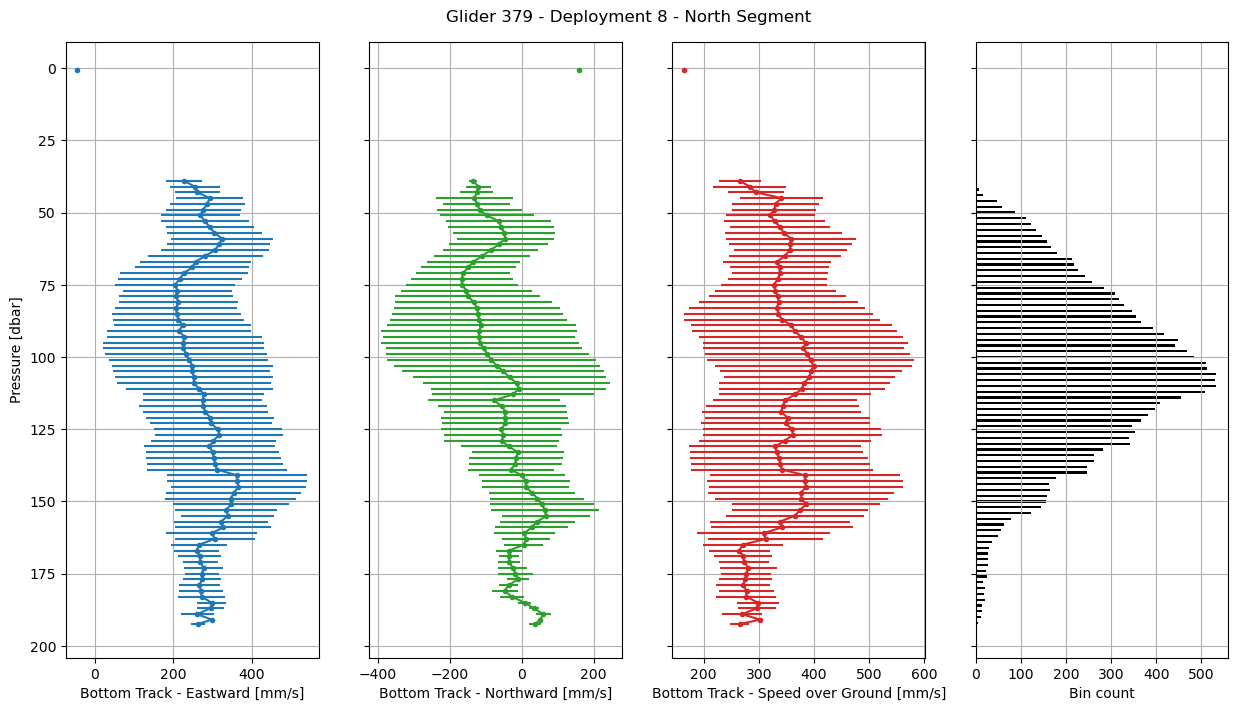

In [119]:
# Plot the profiles
fig, ax = plt.subplots(nrows=1, ncols = 4, figsize=(15, 8), sharey=True)

ax[0].errorbar(avg['bottom_track_eastward_velocity'], avg['ctd_pressure'], xerr=std['bottom_track_eastward_velocity'], marker='.')
ax[0].grid()
ax[0].set_xlabel('Bottom Track - Eastward [mm/s]')
ax[0].set_ylabel('Pressure [dbar]')
ax[0].invert_yaxis()

ax[1].errorbar(avg['bottom_track_northward_velocity'], avg['ctd_pressure'], xerr=std['bottom_track_northward_velocity'], marker='.', color='tab:green')
ax[1].grid()
ax[1].set_xlabel('Bottom Track - Northward [mm/s]')
#ax[1].set_title('Glider 379 - Deployment 8 - North Segment')

ax[2].errorbar(avg['speed_over_ground'], avg['ctd_pressure'], xerr=std['speed_over_ground'], marker='.', color='tab:red')
ax[2].grid()
ax[2].set_xlabel('Bottom Track - Speed over Ground [mm/s]')

ax[3].barh(pres[1:], count['speed_over_ground'], color='black')
ax[3].set_xlabel('Bin count')
ax[3].grid()

fig.suptitle('Glider 379 - Deployment 8 - North Segment', y=0.92)

In [120]:
fig.savefig("../results/figures/GL379.deployment0008.north_segment.bottom_track.png", facecolor='white', transparent=False, bbox_inches='tight')

### Remove Bottom-Track from Velocity Profiles

In [127]:
# First, need to interpolate the bottom_track values on a given profile to 
dive731['ctd_pressure']

<xarray.DataArray 'ctd_pressure' (time: 221)> Size: 2kB
array([ 13.76012245,  13.42555735,  13.53562929,  13.62616195,
        13.54066427,  13.56359581,  13.67240932,  13.78589207,
        13.82443111,  13.92843958,  14.09277362,  14.21395909,
        14.3140454 ,  14.55057741,  14.68058299,  14.95376896,
        15.22295522,  15.50986031,  15.83012633,  16.19561444,
        16.75388282,  17.06002136,  17.58082449,  18.10169424,
        18.67867888,  19.27626602,  19.78445545,  20.49572686,
        20.93058082,  21.57606141,  22.28797716,  22.89196454,
        23.49094359,  24.1934208 ,  24.67889491,  25.43669992,
        26.1462691 ,  26.60430338,  27.32462616,  27.84473733,
        28.57253823,  29.12534627,  29.74499302,  30.40055419,
        31.01367012,  31.81870145,  32.27883982,  33.04418134,
        33.55330002,  34.0853994 ,  34.85970778,  35.49178448,
        36.1182578 ,  36.73724412,  37.43816233,  38.03141635,
        38.69470955,  39.23201315,  39.96856052,  40.58880586,
        41.23445707,  41.8474146 ,  42.45170674,  43.1032732 ,
        43.84721059,  44.45618655,  44.94783277,  45.82961656,
        46.28733566,  46.92930687,  47.62581899,  48.06418706,
        48.92475454,  49.45735797,  50.137234  ,  50.68764496,
        51.32909769,  51.95897716,  52.56837406,  53.15806467,
...
        93.10053086,  93.60398705,  94.23999948,  94.76011722,
        95.29284875,  95.80502649,  96.42676931,  96.94841379,
        97.36833328,  97.84745087,  98.35384724,  98.93735627,
        99.49918646, 100.02298761, 100.54066576, 101.06468747,
       101.65759546, 102.1145839 , 102.64580086, 103.18016123,
       103.67564244, 104.29430361, 104.77062911, 105.24070871,
       105.70220766, 106.20197771, 106.77007461, 107.29771432,
       107.94970445, 108.46055585, 109.09314767, 109.4949542 ,
       109.97082756, 110.56510839, 111.06955396, 111.56854891,
       112.00712823, 112.44296945, 113.043865  , 113.55923124,
       114.09457865, 114.55186453, 115.03092529, 115.53970787,
       115.92644986, 116.36565037, 116.94644388, 117.38673028,
       117.91975689, 118.3355637 , 118.82418634, 119.39725903,
       119.83657325, 120.30207669, 120.86647327, 121.35200663,
       121.85156466, 122.32855953, 122.81822838, 123.4468113 ,
       123.80505162, 124.30618953, 124.87908735, 125.28831774,
       125.7721266 , 126.34551985, 126.7345828 , 127.09634837,
       127.69005803, 128.11995015, 128.47369891, 129.04781939,
       129.4714282 , 129.79009499, 130.3587109 , 130.51916496,
       130.63319962])
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes: (12/25)
    _ChunkSizes:            350
    accuracy:               0.01
    actual_range:           [-4.0000e-02  9.7106e+02]
    ancillary_variables:      qartod_pressure_flat_line_flag qartod_pressure_...
    axis:                   Z
    bytes:                  4
    ...                     ...
    resolution:             0.01
    source_sensor:          sci_water_pressure
    standard_name:          sea_water_pressure
    units:                  dbar
    valid_max:              2000.0
    valid_min:              0.0

In [128]:
def remove_bottom_track(glider, bottom_track):
    """Remove the bottom track from the glider DVL water velocities"""
    # Adjust the eastward velocities
    east_bottom_track = bottom_track['bt_eastward_velocity'] / 1000
    eastward_velocity = glider['eastward_seawater_velocity'] - east_bottom_track

    # Adjust the nortward velocities
    north_bottom_track = bottom_track['bt_northward_velocity'] / 1000
    northward_velocity = glider['northward_seawater_velocity'] - north_bottom_track

    # Add the results into the glider dataset
    glider['corrected_eastward_velocity'] = eastward_velocity
    glider['corrected_eastward_velocity'].attrs = {
        'standard_name': 'eastward_seawater_velocity',
        'long_name': 'Motion-Corrected Eastward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Eastward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the eastward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'eastward_seawater_velocity bt_eastward_velocity'
    }

    glider['corrected_northward_velocity'] = northward_velocity
    glider['corrected_northward_velocity'].attrs = {
        'standard_name': 'northward_seawater_velocity',
        'long_name': 'Motion-Corrected Northward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Northward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the northward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'northward_seawater_velocity bt_northward_velocity'
    }

    return glider

In [129]:
adj_dive731 = remove_bottom_track(dive731, bottom_track)

In [130]:
adj_dive731

<xarray.Dataset> Size: 1MB
Dimensions:                                    (time: 221, bin: 30)
Coordinates:
    lon                                        (time) float64 2kB -70.88 ... ...
    depth                                      (time) float64 2kB 0.0 ... 0.0
    lat                                        (time) float64 2kB 40.1 ... 40.1
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 2kB 2019...
Data variables: (12/71)
    corrected_echo_intensity_beam4             (time, bin) float64 53kB 50.63...
    num_cells                                  (time) float32 884B 30.0 ... 30.0
    ensemble_number                            (time) float32 884B 1.0 ... 221.0
    transducer_depth                           (time) float32 884B 135.0 ... ...
    corrected_echo_intensity_beam3             (time, bin) float64 53kB 62.22...
    corrected_echo_intensity_beam2             (time, bin) float64 53kB 58.56...
    ...                                         ...
    waypoint_lat                               (time) float64 2kB 39.83 ... 3...
    waypoint_lon                               (time) float64 2kB -71.17 ... ...
    bottom_track_eastward_velocity             (time) float32 884B nan ... 200.0
    bottom_track_northward_velocity            (time) float32 884B nan ... -1...
    corrected_eastward_velocity                (time, bin) float64 53kB nan ....
    corrected_northward_velocity               (time, bin) float64 53kB nan ....
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [131]:
adj_dive731['corrected_eastward_velocity']

<xarray.DataArray 'corrected_eastward_velocity' (time: 221, bin: 30)> Size: 53kB
array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [0.09107563, 0.07148715, 0.0508773 , ...,        nan,        nan,
               nan],
       [0.04266983, 0.03408418, 0.05869642, ...,        nan,        nan,
               nan],
       [0.04720986, 0.07015407, 0.11868697, ...,        nan,        nan,
               nan]], shape=(221, 30))
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * bin      (bin) int32 120B 0 1 2 3 4 5 6 7 8 9 ... 21 22 23 24 25 26 27 28 29
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes:
    standard_name:        eastward_seawater_velocity
    long_name:            Motion-Corrected Eastward Seawater Velocity
    units:                m s-1
    comment:              Eastward seawater velocity component in Earth coord...
    ancillary_variables:  eastward_seawater_velocity bt_eastward_velocity

In [1]:
# Load the datasets

In [16]:
import os, sys, re, ast
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
glider = xr.open_dataset("../data/processed/CP05MOAS-GL379.deployment0008.merged.nc")
glider

<xarray.Dataset> Size: 3GB
Dimensions:                                    (time: 604054, bin: 30)
Coordinates:
    lon                                        (time) float64 5MB ...
    depth                                      (time) float64 5MB ...
    lat                                        (time) float64 5MB ...
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 5MB 2019...
Data variables: (12/67)
    corrected_echo_intensity_beam4             (time, bin) float64 145MB ...
    num_cells                                  (time) float32 2MB ...
    ensemble_number                            (time) float32 2MB ...
    transducer_depth                           (time) float32 2MB ...
    corrected_echo_intensity_beam3             (time, bin) float64 145MB ...
    corrected_echo_intensity_beam2             (time, bin) float64 145MB ...
    ...                                         ...
    glider_precise_lon                         (time) float64 5MB ...
    glider_roll                                (time) float64 5MB ...
    profile_id                                 (time) int64 5MB ...
    vendor_qc_flag                             (time, bin) int64 145MB ...
    waypoint_lat                               (time) float64 5MB ...
    waypoint_lon                               (time) float64 5MB ...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [5]:
bottom_track = xr.open_dataset("../data/raw//CP05MOAS-GL379-01-ADCPAM000.deployment0008.adcp_bottom_track.nc")
bottom_track.load()

<xarray.Dataset> Size: 167MB
Dimensions:                          (time: 604054)
Coordinates:
    lon                              (time) float64 5MB -70.6 -70.6 ... -70.53
    depth                            (time) float64 5MB 0.2459 0.306 ... 102.2
  * time                             (time) datetime64[ns] 5MB 2019-09-27T12:...
    lat                              (time) float64 5MB 40.05 40.05 ... 40.12
Data variables: (12/51)
    bt_beam4_ref_intensity           (time) float32 2MB 67.0 66.0 ... nan nan
    bt_beam1_percent_good            (time) float32 2MB nan nan nan ... nan nan
    bt_beam2_rssi_amplitude          (time) float32 2MB nan nan ... 158.0 162.0
    bt_beam4_ref_correlation         (time) float32 2MB 109.0 104.0 ... nan nan
    bt_beam2_correlation             (time) float32 2MB nan nan ... 255.0 255.0
    bt_gain                          (time) float32 2MB nan 15.0 ... 15.0 15.0
    ...                               ...
    bt_upward_ref_layer_velocity     (time) float32 2MB -292.0 -81.0 ... nan nan
    bt_beam3_correlation             (time) float32 2MB nan nan ... 255.0 255.0
    bt_beam3_range                   (time) float64 5MB nan nan ... 2.21e+03
    bt_beam2_ref_intensity           (time) float32 2MB 71.0 72.0 ... nan nan
    bt_beam2_eval_amp                (time) float32 2MB nan nan ... 56.0 55.0
    bt_ref_layer_near                (time) float32 2MB 80.0 80.0 ... 0.0 0.0
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_bottom_track_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -71.18116628263888
    geospatial_lon_max:                 -70.30236914112658
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [7]:
def remove_bottom_track(glider, bottom_track):
    """Remove the bottom track from the glider DVL water velocities"""
    # Adjust the eastward velocities
    east_bottom_track = bottom_track['bt_eastward_velocity'] / 1000
    eastward_velocity = glider['eastward_seawater_velocity'] - east_bottom_track

    # Adjust the nortward velocities
    north_bottom_track = bottom_track['bt_northward_velocity'] / 1000
    northward_velocity = glider['northward_seawater_velocity'] - north_bottom_track

    # Add the results into the glider dataset
    glider['corrected_eastward_velocity'] = eastward_velocity
    glider['corrected_eastward_velocity'].attrs = {
        'standard_name': 'eastward_seawater_velocity',
        'long_name': 'Motion-Corrected Eastward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Eastward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the eastward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'eastward_seawater_velocity bt_eastward_velocity'
    }

    glider['corrected_northward_velocity'] = northward_velocity
    glider['corrected_northward_velocity'].attrs = {
        'standard_name': 'northward_seawater_velocity',
        'long_name': 'Motion-Corrected Northward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Northward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the northward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'northward_seawater_velocity bt_northward_velocity'
    }

    return glider
    

In [9]:
# Add the eastward and northward bottom track velocities to the glider dataset
glider['bottom_track_eastward_velocity'] = bottom_track['bt_eastward_velocity']
glider['bottom_track_northward_velocity'] = bottom_track['bt_northward_velocity']

### Bottom-Track Statistics
Next, calculate some of the statistics for the bottom track data

##### Glider 379 - Deployment 8 - Dive 731

In [11]:
dive731 = glider.where(glider['profile_id'] == 731, drop=True)
dive731

<xarray.Dataset> Size: 1MB
Dimensions:                                    (time: 221, bin: 30)
Coordinates:
    lon                                        (time) float64 2kB -70.88 ... ...
    depth                                      (time) float64 2kB 0.0 ... 0.0
    lat                                        (time) float64 2kB 40.1 ... 40.1
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 2kB 2019...
Data variables: (12/69)
    corrected_echo_intensity_beam4             (time, bin) float64 53kB 50.63...
    num_cells                                  (time) float32 884B 30.0 ... 30.0
    ensemble_number                            (time) float32 884B 1.0 ... 221.0
    transducer_depth                           (time) float32 884B 135.0 ... ...
    corrected_echo_intensity_beam3             (time, bin) float64 53kB 62.22...
    corrected_echo_intensity_beam2             (time, bin) float64 53kB 58.56...
    ...                                         ...
    profile_id                                 (time) float64 2kB 731.0 ... 7...
    vendor_qc_flag                             (time, bin) float64 53kB 1.0 ....
    waypoint_lat                               (time) float64 2kB 39.83 ... 3...
    waypoint_lon                               (time) float64 2kB -71.17 ... ...
    bottom_track_eastward_velocity             (time) float32 884B nan ... 200.0
    bottom_track_northward_velocity            (time) float32 884B nan ... -1...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [13]:
# Calculate the mean northward and eastward bottom_track velocitys
eastward_velocity = dive731['bottom_track_eastward_velocity'].mean(dim='time', skipna=True).values
northward_velocity = dive731['bottom_track_northward_velocity'].mean(dim='time', skipna=True).values
eastward_velocity, northward_velocity

(array(180.6378, dtype=float32), array(-178.70079, dtype=float32))

In [14]:
eastward_velocity = dive731['bottom_track_eastward_velocity'].std(dim='time', skipna=True).values
northward_velocity = dive731['bottom_track_northward_velocity'].std(dim='time', skipna=True).values
eastward_velocity, northward_velocity

(array(103.54387, dtype=float32), array(79.082664, dtype=float32))

In [92]:
sog = np.sqrt(dive731['bottom_track_eastward_velocity']**2 + dive731['bottom_track_northward_velocity']**2)
glider['speed_over_ground'] = np.sqrt(glider['bottom_track_eastward_velocity']**2 + glider['bottom_track_northward_velocity']**2)

Text(0.5, 0, 'Bottom Track - Speed over Ground [mm/s]')

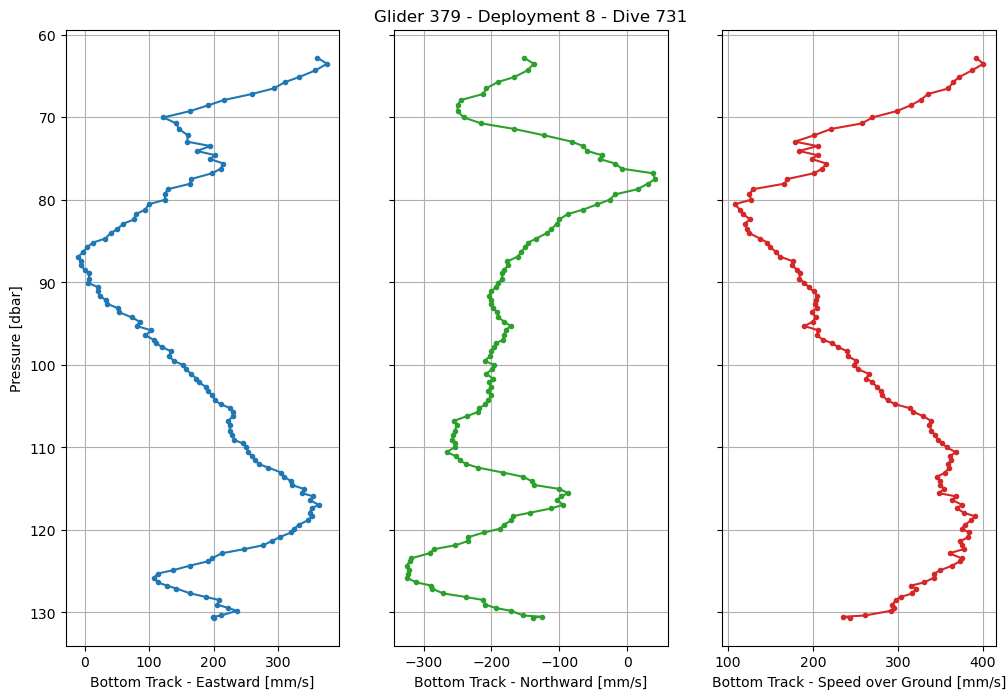

In [48]:
# Plot the profiles
fig, ax = plt.subplots(nrows=1, ncols = 3, figsize=(12, 8), sharey=True)

ax[0].plot(dive731['bottom_track_eastward_velocity'], dive731['ctd_pressure'], marker='.')
ax[0].grid()
ax[0].set_xlabel('Bottom Track - Eastward [mm/s]')
ax[0].set_ylabel('Pressure [dbar]')
ax[0].invert_yaxis()

ax[1].plot(dive731['bottom_track_northward_velocity'], dive731['ctd_pressure'], marker='.', color='tab:green')
ax[1].grid()
ax[1].set_xlabel('Bottom Track - Northward [mm/s]')
ax[1].set_title('Glider 379 - Deployment 8 - Dive 731')

ax[2].plot(sog, dive731['ctd_pressure'], marker='.', color='tab:red')
ax[2].grid()
ax[2].set_xlabel('Bottom Track - Speed over Ground [mm/s]')

# ax[3].plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
# ax[3].grid()
# ax[3].set_xlabel('Vertical Speed (dZ/dt) [mm/s]')


In [49]:
fig.savefig("../results/figures/GL379.deployment0008.dive731.bottom_track.png", facecolor='white', transparent=False, bbox_inches='tight')

Text(0.5, 1.0, 'Glider 379 - Deployment 8 - Dive 731')

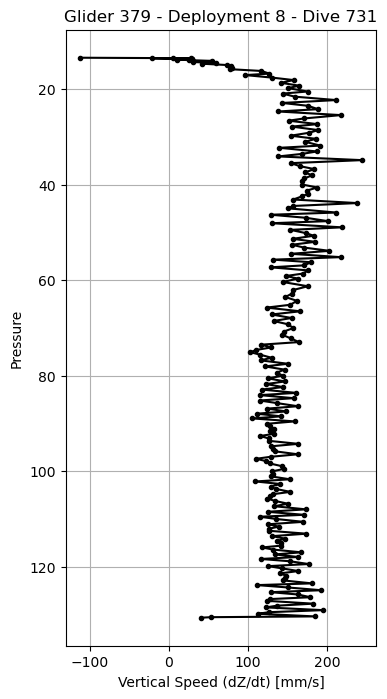

In [50]:
# Calculate the dZ/dt
dZ = dive731['ctd_pressure'].diff(dim='time')
dt = dive731['time'].diff(dim='time').astype(float)/1E9
dZdt = dZ/dt

# Plot the results
fig, ax = plt.subplots(figsize=(4, 8))
ax.plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
ax.set_ylabel('Pressure')
ax.set_xlabel('Vertical Speed (dZ/dt) [mm/s]')
ax.invert_yaxis()
ax.grid()
ax.set_title('Glider 379 - Deployment 8 - Dive 731')
# ax[3].plot(dZdt*1000, dive731['ctd_pressure'][1:], marker='.', color='black')
# ax[3].grid()
# ax[3].set_xlabel('Vertical Speed (dZ/dt) [mm/s]')


In [52]:
fig.savefig("../results/figures/GL379.deployment0008.dive731.dZdt.png", facecolor='white', transparent=False, bbox_inches='tight')

In [54]:
# Grab the segment in which dive 731 is a member of
dive731['lat']

<xarray.DataArray 'lat' (time: 221)> Size: 2kB
array([40.0978126 , 40.09781714, 40.0978206 , 40.09782347, 40.09782973,
       40.09783447, 40.09783771, 40.09784114, 40.09784542, 40.09785174,
       40.09785436, 40.09785786, 40.09786316, 40.09786809, 40.09787082,
       40.09787449, 40.09788051, 40.0978841 , 40.09788769, 40.09789042,
       40.09789584, 40.09790093, 40.09790438, 40.09790733, 40.09791392,
       40.09791802, 40.09792104, 40.09792466, 40.09792764, 40.09793477,
       40.09793778, 40.09794152, 40.09794675, 40.09795169, 40.09795483,
       40.09795795, 40.09796192, 40.09796733, 40.09797161, 40.0979746 ,
       40.0979794 , 40.09798464, 40.09798823, 40.09799138, 40.09799457,
       40.0980009 , 40.09800508, 40.09800873, 40.09801144, 40.09801492,
       40.09802059, 40.09802518, 40.09802857, 40.09803305, 40.09803903,
       40.09804194, 40.09804525, 40.09804811, 40.09805486, 40.09805878,
       40.09806208, 40.09806593, 40.0980722 , 40.0980759 , 40.09807868,
       40.09808214, 40.09808658, 40.09809255, 40.09809572, 40.09809932,
       40.09810551, 40.09810895, 40.09811247, 40.09811614, 40.09812096,
       40.09812464, 40.09812967, 40.09813384, 40.09813817, 40.09814125,
       40.09814428, 40.09815117, 40.09815455, 40.09815802, 40.09816065,
       40.09816454, 40.09817019, 40.09817399, 40.09817751, 40.09818207,
       40.09818715, 40.09819156, 40.09819609, 40.09820299, 40.09820855,
       40.098213  , 40.09822125, 40.09822604, 40.09823028, 40.09823662,
...
       40.09837576, 40.09838035, 40.09838396, 40.09838758, 40.09839407,
       40.09839873, 40.09840231, 40.09840781, 40.09841328, 40.09841704,
       40.09842053, 40.09842543, 40.09843153, 40.09843509, 40.09843923,
       40.09844598, 40.09844968, 40.09845318, 40.09845676, 40.09846314,
       40.09846753, 40.09847095, 40.0984765 , 40.09848199, 40.09848539,
       40.0984888 , 40.09849313, 40.09849957, 40.09850305, 40.09850657,
       40.09851345, 40.09851746, 40.09852105, 40.09852454, 40.09853028,
       40.09853541, 40.09853914, 40.09854373, 40.09855002, 40.09855329,
       40.09855689, 40.09856011, 40.09856642, 40.09857049, 40.0985738 ,
       40.09857875, 40.09858447, 40.09858774, 40.09859139, 40.09859473,
       40.09860096, 40.09860476, 40.09860781, 40.0986127 , 40.09861834,
       40.09862142, 40.09862449, 40.09862753, 40.09863307, 40.09863809,
       40.09864107, 40.09864408, 40.09865024, 40.09865398, 40.09865696,
       40.09866006, 40.09866299, 40.09866848, 40.09867291, 40.09867575,
       40.09867863, 40.09868175, 40.09868691, 40.09869154, 40.09869463,
       40.09869762, 40.09870338, 40.09870736, 40.09871045, 40.09871332,
       40.09871628, 40.09872113, 40.09872555, 40.0987281 , 40.09873096,
       40.09873537, 40.09874011, 40.09874302, 40.09874583, 40.09874946,
       40.09875452, 40.09875748, 40.09875987, 40.09876253, 40.09876782,
       40.09877147])
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes:
    comment:        Interpolated GPS latitude in decimal degrees.
    standard_name:  latitude
    long_name:      Interpolated GPS Latitude
    units:          degree_north
    precision:      4
    axis:           Y

In [93]:
#subset = glider.sel(time=slice('20-10-2019','25-10-2019')).load()
subset = glider.where((glider.profile_id >= 638) & (glider.profile_id <= 782), drop=True)
subset

<xarray.Dataset> Size: 153MB
Dimensions:                                    (time: 32843, bin: 30)
Coordinates:
    lon                                        (time) float64 263kB -70.37 .....
    depth                                      (time) float64 263kB 0.0 ... 0.0
    lat                                        (time) float64 263kB 40.07 ......
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 263kB 20...
Data variables: (12/70)
    corrected_echo_intensity_beam4             (time, bin) float64 8MB 83.57 ...
    num_cells                                  (time) float32 131kB 30.0 ... ...
    ensemble_number                            (time) float32 131kB 1.0 ... 3...
    transducer_depth                           (time) float32 131kB 6.0 ... 1...
    corrected_echo_intensity_beam3             (time, bin) float64 8MB 92.72 ...
    corrected_echo_intensity_beam2             (time, bin) float64 8MB 85.4 ....
    ...                                         ...
    vendor_qc_flag                             (time, bin) float64 8MB 1.0 .....
    waypoint_lat                               (time) float64 263kB 39.83 ......
    waypoint_lon                               (time) float64 263kB -71.17 .....
    bottom_track_eastward_velocity             (time) float32 131kB nan ... 4...
    bottom_track_northward_velocity            (time) float32 131kB nan ... 1...
    speed_over_ground                          (time) float32 131kB nan ... 4...
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [100]:
# Calculate the segment mean bottom-track velocities and their speed-over-ground
# First, need to segment the data into a regularized pressure grid
step = 2
pres = np.arange(0, 200+step, step)

# Take the means and standard deviations
group = subset[['bottom_track_eastward_velocity','bottom_track_northward_velocity','speed_over_ground','ctd_pressure']].groupby_bins(group='ctd_pressure', bins=pres)
avg = group.mean(skipna=True)
std = group.std(skipna=True)
count = group.count()


/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/jovyan/.conda/envs/glider_dvl_analysis/lib/python3.10/site-packages/numpy/lib/_nanfunctions_im

In [103]:
count

<xarray.Dataset> Size: 4kB
Dimensions:                          (ctd_pressure_bins: 100)
Coordinates:
  * ctd_pressure_bins                (ctd_pressure_bins) object 800B (0, 2] ....
Data variables:
    bottom_track_eastward_velocity   (ctd_pressure_bins) float64 800B 1.0 ......
    bottom_track_northward_velocity  (ctd_pressure_bins) float64 800B 1.0 ......
    speed_over_ground                (ctd_pressure_bins) float64 800B 1.0 ......
    ctd_pressure                     (ctd_pressure_bins) float64 800B 694.0 ....
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

Text(0.5, 0.92, 'Glider 379 - Deployment 8 - North Segment')

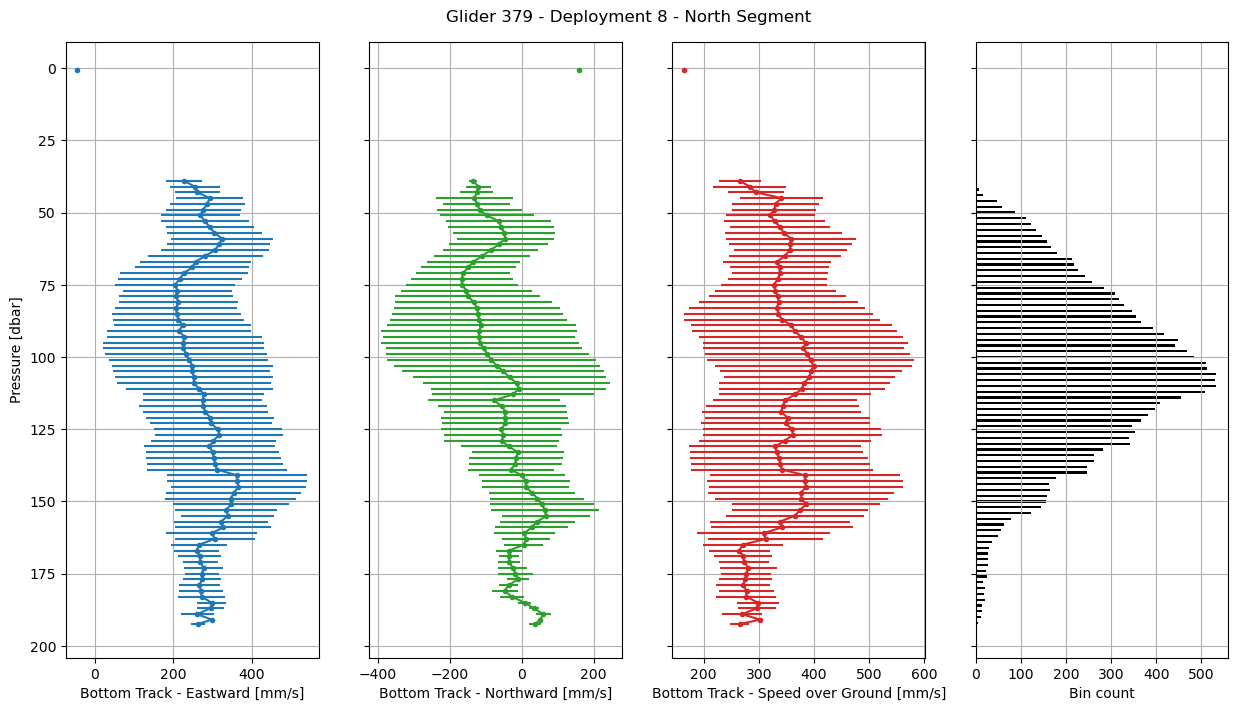

In [119]:
# Plot the profiles
fig, ax = plt.subplots(nrows=1, ncols = 4, figsize=(15, 8), sharey=True)

ax[0].errorbar(avg['bottom_track_eastward_velocity'], avg['ctd_pressure'], xerr=std['bottom_track_eastward_velocity'], marker='.')
ax[0].grid()
ax[0].set_xlabel('Bottom Track - Eastward [mm/s]')
ax[0].set_ylabel('Pressure [dbar]')
ax[0].invert_yaxis()

ax[1].errorbar(avg['bottom_track_northward_velocity'], avg['ctd_pressure'], xerr=std['bottom_track_northward_velocity'], marker='.', color='tab:green')
ax[1].grid()
ax[1].set_xlabel('Bottom Track - Northward [mm/s]')
#ax[1].set_title('Glider 379 - Deployment 8 - North Segment')

ax[2].errorbar(avg['speed_over_ground'], avg['ctd_pressure'], xerr=std['speed_over_ground'], marker='.', color='tab:red')
ax[2].grid()
ax[2].set_xlabel('Bottom Track - Speed over Ground [mm/s]')

ax[3].barh(pres[1:], count['speed_over_ground'], color='black')
ax[3].set_xlabel('Bin count')
ax[3].grid()

fig.suptitle('Glider 379 - Deployment 8 - North Segment', y=0.92)

In [120]:
fig.savefig("../results/figures/GL379.deployment0008.north_segment.bottom_track.png", facecolor='white', transparent=False, bbox_inches='tight')

### Remove Bottom-Track from Velocity Profiles

In [127]:
# First, need to interpolate the bottom_track values on a given profile to 
dive731['ctd_pressure']

<xarray.DataArray 'ctd_pressure' (time: 221)> Size: 2kB
array([ 13.76012245,  13.42555735,  13.53562929,  13.62616195,
        13.54066427,  13.56359581,  13.67240932,  13.78589207,
        13.82443111,  13.92843958,  14.09277362,  14.21395909,
        14.3140454 ,  14.55057741,  14.68058299,  14.95376896,
        15.22295522,  15.50986031,  15.83012633,  16.19561444,
        16.75388282,  17.06002136,  17.58082449,  18.10169424,
        18.67867888,  19.27626602,  19.78445545,  20.49572686,
        20.93058082,  21.57606141,  22.28797716,  22.89196454,
        23.49094359,  24.1934208 ,  24.67889491,  25.43669992,
        26.1462691 ,  26.60430338,  27.32462616,  27.84473733,
        28.57253823,  29.12534627,  29.74499302,  30.40055419,
        31.01367012,  31.81870145,  32.27883982,  33.04418134,
        33.55330002,  34.0853994 ,  34.85970778,  35.49178448,
        36.1182578 ,  36.73724412,  37.43816233,  38.03141635,
        38.69470955,  39.23201315,  39.96856052,  40.58880586,
        41.23445707,  41.8474146 ,  42.45170674,  43.1032732 ,
        43.84721059,  44.45618655,  44.94783277,  45.82961656,
        46.28733566,  46.92930687,  47.62581899,  48.06418706,
        48.92475454,  49.45735797,  50.137234  ,  50.68764496,
        51.32909769,  51.95897716,  52.56837406,  53.15806467,
...
        93.10053086,  93.60398705,  94.23999948,  94.76011722,
        95.29284875,  95.80502649,  96.42676931,  96.94841379,
        97.36833328,  97.84745087,  98.35384724,  98.93735627,
        99.49918646, 100.02298761, 100.54066576, 101.06468747,
       101.65759546, 102.1145839 , 102.64580086, 103.18016123,
       103.67564244, 104.29430361, 104.77062911, 105.24070871,
       105.70220766, 106.20197771, 106.77007461, 107.29771432,
       107.94970445, 108.46055585, 109.09314767, 109.4949542 ,
       109.97082756, 110.56510839, 111.06955396, 111.56854891,
       112.00712823, 112.44296945, 113.043865  , 113.55923124,
       114.09457865, 114.55186453, 115.03092529, 115.53970787,
       115.92644986, 116.36565037, 116.94644388, 117.38673028,
       117.91975689, 118.3355637 , 118.82418634, 119.39725903,
       119.83657325, 120.30207669, 120.86647327, 121.35200663,
       121.85156466, 122.32855953, 122.81822838, 123.4468113 ,
       123.80505162, 124.30618953, 124.87908735, 125.28831774,
       125.7721266 , 126.34551985, 126.7345828 , 127.09634837,
       127.69005803, 128.11995015, 128.47369891, 129.04781939,
       129.4714282 , 129.79009499, 130.3587109 , 130.51916496,
       130.63319962])
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes: (12/25)
    _ChunkSizes:            350
    accuracy:               0.01
    actual_range:           [-4.0000e-02  9.7106e+02]
    ancillary_variables:      qartod_pressure_flat_line_flag qartod_pressure_...
    axis:                   Z
    bytes:                  4
    ...                     ...
    resolution:             0.01
    source_sensor:          sci_water_pressure
    standard_name:          sea_water_pressure
    units:                  dbar
    valid_max:              2000.0
    valid_min:              0.0

In [128]:
def remove_bottom_track(glider, bottom_track):
    """Remove the bottom track from the glider DVL water velocities"""
    # Adjust the eastward velocities
    east_bottom_track = bottom_track['bt_eastward_velocity'] / 1000
    eastward_velocity = glider['eastward_seawater_velocity'] - east_bottom_track

    # Adjust the nortward velocities
    north_bottom_track = bottom_track['bt_northward_velocity'] / 1000
    northward_velocity = glider['northward_seawater_velocity'] - north_bottom_track

    # Add the results into the glider dataset
    glider['corrected_eastward_velocity'] = eastward_velocity
    glider['corrected_eastward_velocity'].attrs = {
        'standard_name': 'eastward_seawater_velocity',
        'long_name': 'Motion-Corrected Eastward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Eastward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the eastward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'eastward_seawater_velocity bt_eastward_velocity'
    }

    glider['corrected_northward_velocity'] = northward_velocity
    glider['corrected_northward_velocity'].attrs = {
        'standard_name': 'northward_seawater_velocity',
        'long_name': 'Motion-Corrected Northward Seawater Velocity',
        'units': 'm s-1',
        'comment': ('Northward seawater velocity component in Earth coordinates. The motion of the '
                    'glider has been removed by subtracting the northward velocity measured by the '
                    'bottom tracking, when available'),
        'ancillary_variables': 'northward_seawater_velocity bt_northward_velocity'
    }

    return glider

In [129]:
adj_dive731 = remove_bottom_track(dive731, bottom_track)

In [130]:
adj_dive731

<xarray.Dataset> Size: 1MB
Dimensions:                                    (time: 221, bin: 30)
Coordinates:
    lon                                        (time) float64 2kB -70.88 ... ...
    depth                                      (time) float64 2kB 0.0 ... 0.0
    lat                                        (time) float64 2kB 40.1 ... 40.1
  * bin                                        (bin) int32 120B 0 1 2 ... 28 29
  * time                                       (time) datetime64[ns] 2kB 2019...
Data variables: (12/71)
    corrected_echo_intensity_beam4             (time, bin) float64 53kB 50.63...
    num_cells                                  (time) float32 884B 30.0 ... 30.0
    ensemble_number                            (time) float32 884B 1.0 ... 221.0
    transducer_depth                           (time) float32 884B 135.0 ... ...
    corrected_echo_intensity_beam3             (time, bin) float64 53kB 62.22...
    corrected_echo_intensity_beam2             (time, bin) float64 53kB 58.56...
    ...                                         ...
    waypoint_lat                               (time) float64 2kB 39.83 ... 3...
    waypoint_lon                               (time) float64 2kB -71.17 ... ...
    bottom_track_eastward_velocity             (time) float32 884B nan ... 200.0
    bottom_track_northward_velocity            (time) float32 884B nan ... -1...
    corrected_eastward_velocity                (time, bin) float64 53kB nan ....
    corrected_northward_velocity               (time, bin) float64 53kB nan ....
Attributes: (12/67)
    node:                               GL379
    comment:                            Data produced by the OOI M2M API and ...
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_host
    stream:                             adcp_velocity_earth
    ...                                 ...
    geospatial_lat_units:               degrees_north
    geospatial_lat_resolution:          0.1
    geospatial_lon_min:                 -70.65249279445464
    geospatial_lon_max:                 -70.37325248678327
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1

In [131]:
adj_dive731['corrected_eastward_velocity']

<xarray.DataArray 'corrected_eastward_velocity' (time: 221, bin: 30)> Size: 53kB
array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [0.09107563, 0.07148715, 0.0508773 , ...,        nan,        nan,
               nan],
       [0.04266983, 0.03408418, 0.05869642, ...,        nan,        nan,
               nan],
       [0.04720986, 0.07015407, 0.11868697, ...,        nan,        nan,
               nan]], shape=(221, 30))
Coordinates:
    lon      (time) float64 2kB -70.88 -70.88 -70.88 ... -70.88 -70.88 -70.88
    depth    (time) float64 2kB 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    lat      (time) float64 2kB 40.1 40.1 40.1 40.1 40.1 ... 40.1 40.1 40.1 40.1
  * bin      (bin) int32 120B 0 1 2 3 4 5 6 7 8 9 ... 21 22 23 24 25 26 27 28 29
  * time     (time) datetime64[ns] 2kB 2019-10-23T09:42:37.729999872 ... 2019...
Attributes:
    standard_name:        eastward_seawater_velocity
    long_name:            Motion-Corrected Eastward Seawater Velocity
    units:                m s-1
    comment:              Eastward seawater velocity component in Earth coord...
    ancillary_variables:  eastward_seawater_velocity bt_eastward_velocity